In [ ]:
# install Dependencies
!pip install ultralytics albumentations torchmetrics opencv-python-headless -q


[notice] A new release of pip is available: 23.0.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import os, sys, json, random, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from collections import Counter
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead
from functools import partial

warnings.filterwarnings('ignore')

In [3]:
if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
print(f'Device: {DEVICE}')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ── Path Konfigurasi ─────────────────────────────────────────────────────────
BASE_DIR   = Path('dataset')
TRAIN_IMG  = BASE_DIR / 'train'  / 'images'
TRAIN_LBL  = BASE_DIR / 'train'  / 'labels'
VALID_IMG  = BASE_DIR / 'valid'  / 'images'
VALID_LBL  = BASE_DIR / 'valid'  / 'labels'
TEST_IMG   = BASE_DIR / 'test'   / 'images'
TEST_LBL   = BASE_DIR / 'test'   / 'labels'
DATA_YAML  = BASE_DIR / 'data.yaml'
OUTPUT_DIR = Path('outputs'); OUTPUT_DIR.mkdir(exist_ok=True)

# ── Kelas & Warna ────────────────────────────────────────────────────────────
CLASS_NAMES  = ['kardiomegali', 'normal']
CLASS_COLORS = ['#FF6B6B', '#4ECDC4']

# ── Hyperparameter ───────────────────────────────────────────────────────────
YOLO_SIZE   = 512   # YOLOv11 input size
SSD_SIZE    = 300   # SSD300 input size (sesuai arsitektur anchor VGG16)
NUM_CLASSES = 3     # 0=background, 1=kardiomegali, 2=normal (SSD)
YOLO_EPOCHS = 25
SSD_EPOCHS  = 25

print(f'Dataset : {BASE_DIR.resolve()}')
print(f'YOLO size image : {YOLO_SIZE} | SSD size image : {SSD_SIZE}')

Device: mps
Dataset : /Users/mochammadirsyadkurniawan/UMB - Materi & Tugas/semester 8/yolo11/dataset
YOLO size image : 512 | SSD size image : 300


In [4]:
def parse_yolo_labels(img_dir, lbl_dir):
    records = []
    for img_path in sorted(img_dir.glob('*.*')):
        if img_path.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
            continue
        lbl_path = lbl_dir / (img_path.stem + '.txt')
        img = Image.open(img_path)
        w, h = img.size
        boxes = []
        if lbl_path.exists():
            for line in lbl_path.read_text().strip().splitlines():
                parts = line.strip().split()
                if len(parts) == 5:
                    cls = int(parts[0])
                    cx, cy, bw, bh = map(float, parts[1:])
                    boxes.append({'class': cls, 'name': CLASS_NAMES[cls],
                                  'cx': cx, 'cy': cy, 'bw': bw, 'bh': bh,
                                  'area': bw * bh})
        records.append({'file': img_path.name, 'width': w, 'height': h,
                        'n_boxes': len(boxes), 'boxes': boxes})
    return records

train_data = parse_yolo_labels(TRAIN_IMG, TRAIN_LBL)
valid_data = parse_yolo_labels(VALID_IMG, VALID_LBL)
test_data  = parse_yolo_labels(TEST_IMG,  TEST_LBL)

def flatten_boxes(records, split):
    rows = []
    for r in records:
        for b in r['boxes']:
            rows.append({**b, 'file': r['file'], 'split': split,
                         'img_w': r['width'], 'img_h': r['height']})
    return rows

df = pd.DataFrame(
    flatten_boxes(train_data, 'train') +
    flatten_boxes(valid_data, 'valid') +
    flatten_boxes(test_data,  'test')
)

print('\nDistribusi Kelas per Split:')
print(df.groupby(['split', 'name']).size().unstack(fill_value=0))
print(f'\n📂 Total Gambar: Train={len(train_data)} | Valid={len(valid_data)} | Test={len(test_data)}')


Distribusi Kelas per Split:
name   kardiomegali  normal
split                      
test             44      47
train           638     642
valid            32      60

📂 Total Gambar: Train=1280 | Valid=92 | Test=91


In [5]:
print('Statistik Dataset')

train_imgs = len(train_data)
valid_imgs = len(valid_data)
test_imgs  = len(test_data)

total_imgs = train_imgs + valid_imgs + test_imgs

print(f'Total gambar : {total_imgs}')
print(f'  Train      : {train_imgs}')
print(f'  Valid      : {valid_imgs}')
print(f'  Test       : {test_imgs}')

Statistik Dataset
Total gambar : 1463
  Train      : 1280
  Valid      : 92
  Test       : 91


In [6]:
def get_split_stats(lbl_dir):
    counts = Counter()
    for lbl_file in Path(lbl_dir).glob('*.txt'):
        with open(lbl_file, 'r') as f:
            lines = f.readlines()
            for line in lines:
                cls_id = int(line.split()[0])
                counts[cls_id] += 1
    return {'class_counts': dict(counts)}

# hitung statistik untuk setiap split
train_stats = get_split_stats(TRAIN_LBL)
valid_stats = get_split_stats(VALID_LBL)
test_stats  = get_split_stats(TEST_LBL)

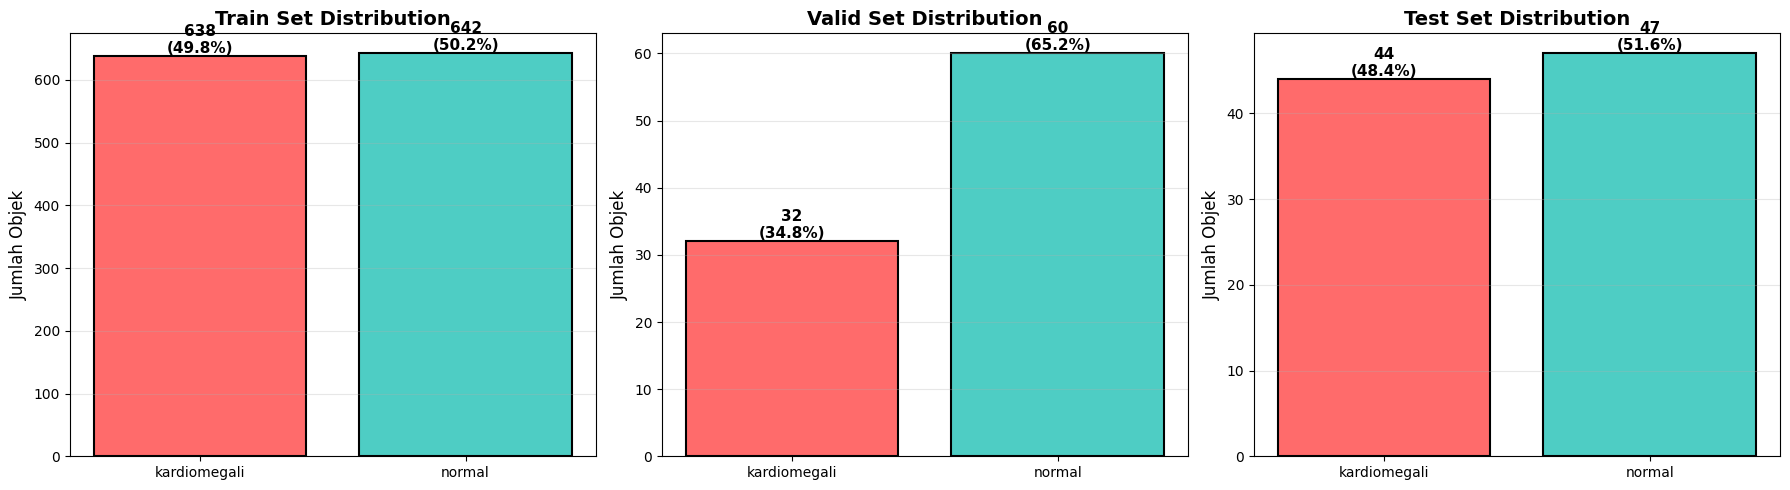


plot saved to: outputs/class_distribution.png


In [7]:
# Visualize class distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

splits = [('Train', train_stats), ('Valid', valid_stats), ('Test', test_stats)]
# colors_list = [COLORS['kardiomegali'], COLORS['normal']]
colors_list = ['#FF6B6B', '#4ECDC4']

for idx, (split_name, stats) in enumerate(splits):
    ax = axes[idx]
    # urutan kelas sesuai (0: kardiomegali, 1: normal)
    counts = [stats['class_counts'].get(0, 0), stats['class_counts'].get(1, 0)]
    
    bars = ax.bar(CLASS_NAMES, counts, color=colors_list, edgecolor='black', linewidth=1.5)
    
    # menambahkan label angka di atas bar
    total = sum(counts)
    for bar, count in zip(bars, counts):
        height = bar.get_height()
        percentage = (count / total * 100) if total > 0 else 0
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{count}\n({percentage:.1f}%)',
                ha='center', va='bottom', fontweight='bold', fontsize=11)
    
    ax.set_title(f'{split_name} Set Distribution', fontsize=14, fontweight='bold')
    ax.set_ylabel('Jumlah Objek', fontsize=12)
    ax.grid(axis='y', alpha=0.3)
    
plt.tight_layout()
plt.savefig(OUTPUT_DIR/ 'class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nplot saved to: {OUTPUT_DIR / 'class_distribution.png'}")

Hasil visualisasi disimpan di: outputs/train_samples_new.png


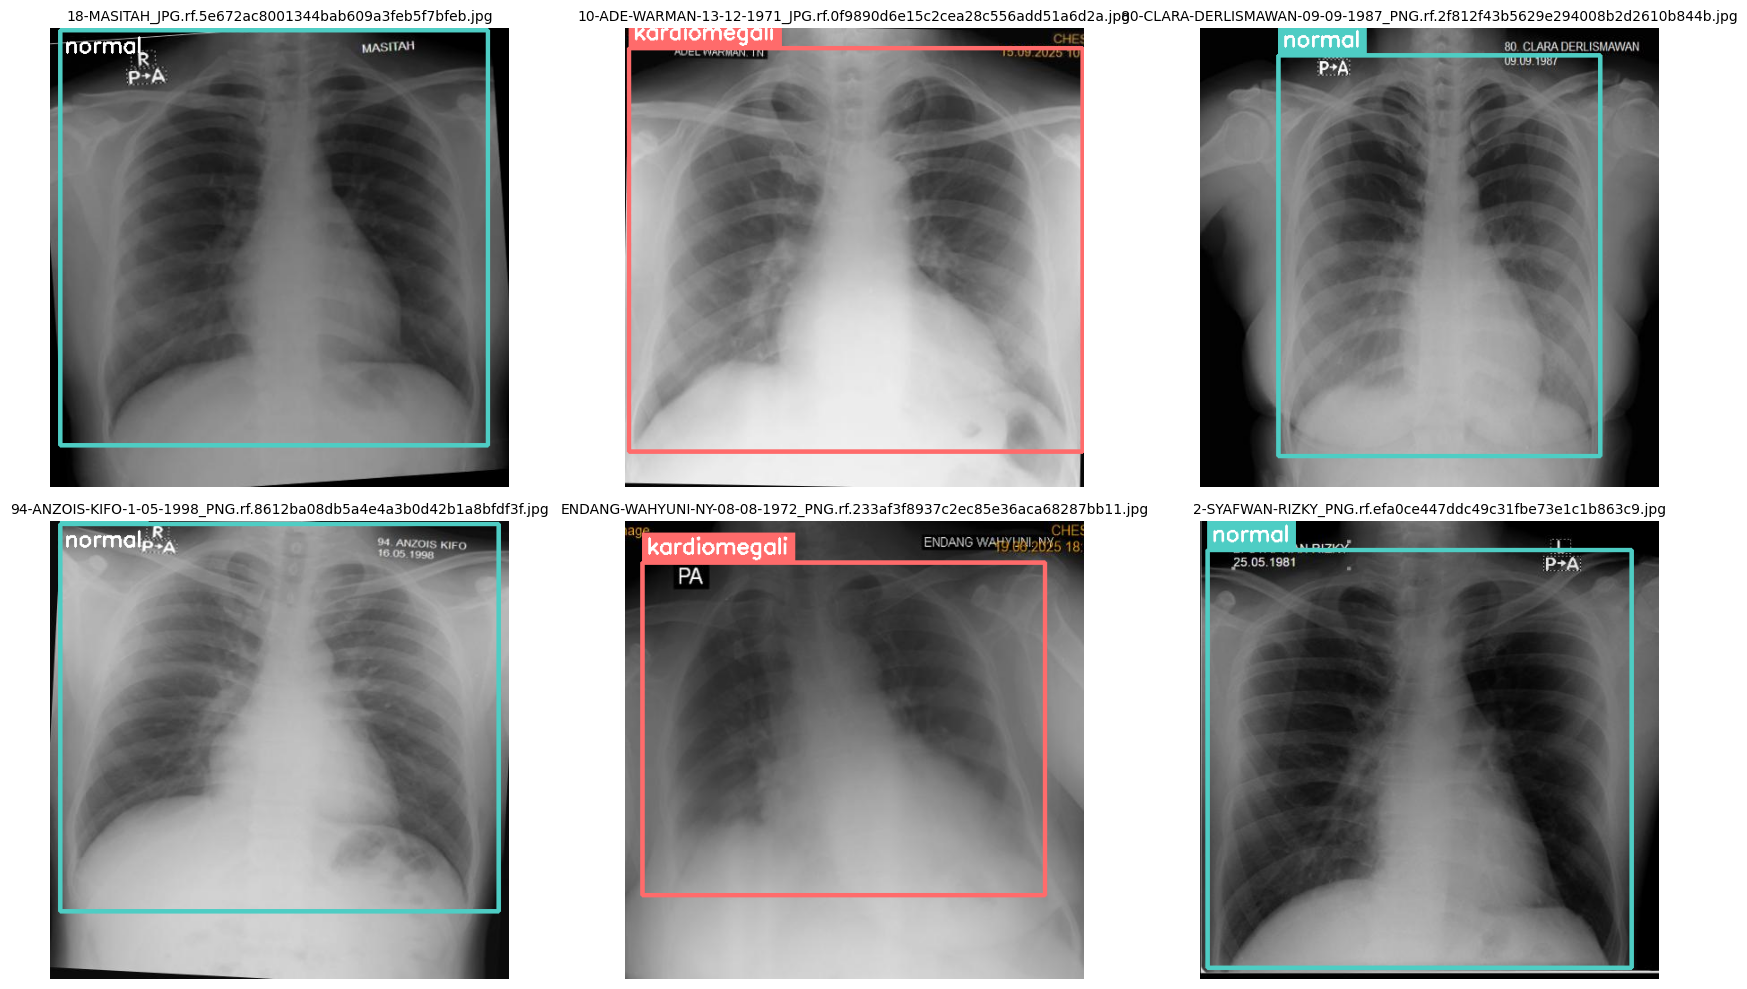

In [8]:
import random
import cv2
import matplotlib.pyplot as plt

def visualize_samples(split='train', num_samples=6):
    
    # mapping folder berdasarkan split
    if split == 'train':
        img_dir, lbl_dir = TRAIN_IMG, TRAIN_LBL
    elif split == 'valid':
        img_dir, lbl_dir = VALID_IMG, VALID_LBL
    elif split == 'test':
        img_dir, lbl_dir = TEST_IMG, TEST_LBL
    else:
        raise ValueError("split harus 'train', 'valid', atau 'test'")
    
    # ambil semua file gambar
    image_files = list(img_dir.glob('*.*'))
    
    if len(image_files) == 0:
        print(f"Tidak ada gambar pada folder: {img_dir}")
        return
    
    random.shuffle(image_files)
    
    # batasi jumlah sample agar tidak melebihi jumlah file
    num_samples = min(num_samples, len(image_files))
    
    # layout subplot
    rows = 2
    cols = (num_samples + 1) // 2
    
    fig, axes = plt.subplots(rows, cols, figsize=(18, 10))
    
    # jika subplot cuma 1, ubah jadi list
    if num_samples == 1:
        axes = [axes]
    else:
        axes = axes.ravel()
    
    # Loop visualisasi
    for idx in range(num_samples):
        img_path = image_files[idx]
        label_path = lbl_dir / f"{img_path.stem}.txt"
        
        # load image
        img = cv2.imread(str(img_path))
        
        if img is None:
            print(f"Gagal membaca gambar: {img_path}")
            continue
        
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        
        # load label YOLO
        if label_path.exists():
            with open(label_path, 'r') as f:
                for line in f.readlines():
                    data = line.strip().split()
                    
                    if len(data) >= 5:
                        class_id = int(data[0])
                        
                        # Validasi class id
                        if class_id >= len(CLASS_NAMES):
                            print(f"Class ID {class_id} tidak valid pada {label_path.name}")
                            continue
                        
                        cx, cy, bw, bh = map(float, data[1:5])
                        
                        # Konversi format YOLO ke pixel
                        x1 = int((cx - bw / 2) * w)
                        y1 = int((cy - bh / 2) * h)
                        x2 = int((cx + bw / 2) * w)
                        y2 = int((cy + bh / 2) * h)
                        
                        # Clamp koordinat biar aman
                        x1 = max(0, x1)
                        y1 = max(0, y1)
                        x2 = min(w, x2)
                        y2 = min(h, y2)
                        
                        # Nama class
                        cls_name = CLASS_NAMES[class_id]
                        
                        # Ambil warna berdasarkan class_id
                        hex_col = CLASS_COLORS[class_id].lstrip('#')
                        rgb_col = tuple(int(hex_col[i:i+2], 16) for i in (0, 2, 4))
                        
                        # Gambar bounding box
                        cv2.rectangle(img, (x1, y1), (x2, y2), rgb_col, 3)
                        
                        # Background label
                        label_txt = cls_name
                        (tw, th), _ = cv2.getTextSize(
                            label_txt,
                            cv2.FONT_HERSHEY_SIMPLEX,
                            0.8,
                            2
                        )
                        
                        label_y1 = max(0, y1 - th - 15)
                        label_y2 = max(0, y1)
                        
                        cv2.rectangle(
                            img,
                            (x1, label_y1),
                            (x1 + tw + 10, label_y2),
                            rgb_col,
                            -1
                        )
                        
                        # Teks label
                        cv2.putText(
                            img,
                            label_txt,
                            (x1 + 5, y1 - 10 if y1 > 20 else y1 + 25),
                            cv2.FONT_HERSHEY_SIMPLEX,
                            0.8,
                            (255, 255, 255),
                            2
                        )
        
        # tampilkan image
        axes[idx].imshow(img)
        axes[idx].set_title(img_path.name, fontsize=10)
        axes[idx].axis('off')
    
    # sembunyikan subplot kosong
    for j in range(num_samples, len(axes)):
        axes[j].axis('off')
    
    plt.tight_layout()
    
    # simpan hasil
    save_path = OUTPUT_DIR / f'{split}_samples_new.png'
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    
    print(f"Hasil visualisasi disimpan di: {save_path}")
    plt.show()


# jalankan visualisasi
visualize_samples(split='train', num_samples=6)

disimpan: outputs/augmentation_steps_visualization.png


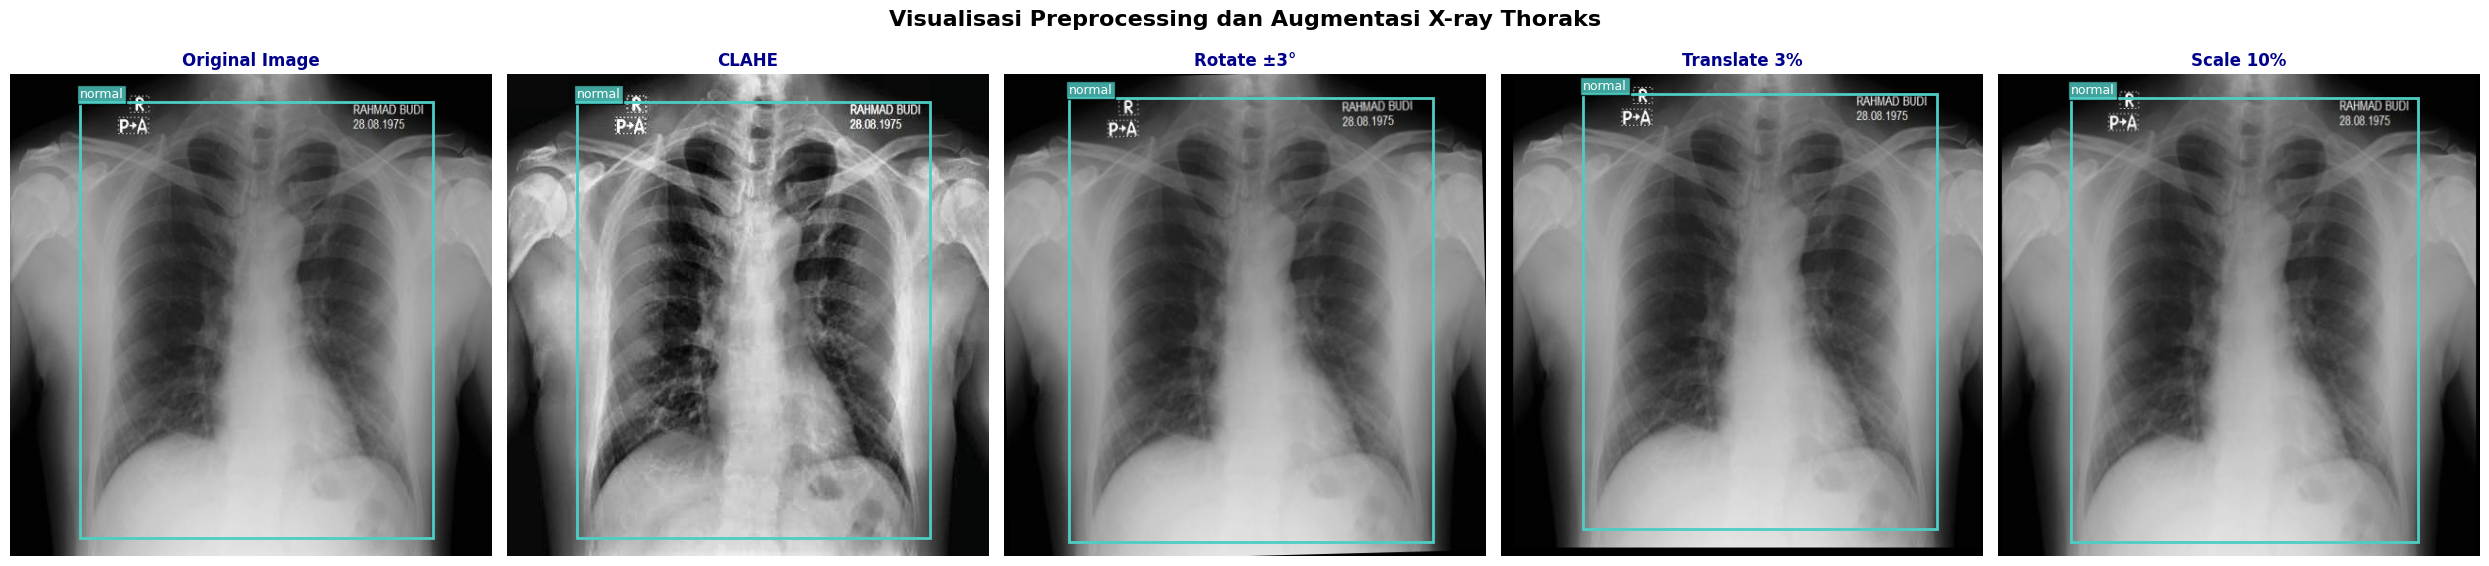

In [9]:
import albumentations as A

def show_augmentation_steps(img_dir, lbl_dir, img_size=512):
    img_files = list(img_dir.glob('*.jpg')) + list(img_dir.glob('*.png'))
    if not img_files:
        print(f'Tidak ada gambar di: {img_dir}'); return

    img_path = random.choice(img_files)
    lbl_path = lbl_dir / f'{img_path.stem}.txt'
    img = np.array(Image.open(img_path).convert('RGB'))

    bboxes, labels = [], []
    if lbl_path.exists():
        for line in lbl_path.read_text().strip().splitlines():
            p = line.strip().split()
            if len(p) == 5:
                cls_id = int(p[0])
                if cls_id < len(CLASS_NAMES):
                    labels.append(cls_id)
                    bboxes.append([float(x) for x in p[1:]])

    bp = A.BboxParams(format='yolo', label_fields=['class_labels'], min_visibility=0.3)
    transforms_list = [
        ('Original Image', None),
        ('CLAHE',           A.Compose([A.Resize(img_size, img_size),
                                       A.CLAHE(clip_limit=(2, 4), p=1.0)], bbox_params=bp)),
        ('Rotate ±3°',      A.Compose([A.Resize(img_size, img_size),
                                       A.Rotate(limit=3, border_mode=cv2.BORDER_CONSTANT, p=1.0)], bbox_params=bp)),
        ('Translate 3%',    A.Compose([A.Resize(img_size, img_size),
                                       A.ShiftScaleRotate(shift_limit=0.03, scale_limit=0,
                                                          rotate_limit=0, border_mode=cv2.BORDER_CONSTANT, p=1.0)], bbox_params=bp)),
        ('Scale 10%',       A.Compose([A.Resize(img_size, img_size),
                                       A.ShiftScaleRotate(shift_limit=0, scale_limit=0.1,
                                                          rotate_limit=0, border_mode=cv2.BORDER_CONSTANT, p=1.0)], bbox_params=bp)),
    ]

    fig, axes = plt.subplots(1, len(transforms_list), figsize=(5 * len(transforms_list), 6))
    for idx, (title, transform) in enumerate(transforms_list):
        if transform is None:
            vis_img, vis_bboxes, vis_labels = img.copy(), bboxes, labels
        else:
            out = transform(image=img, bboxes=bboxes, class_labels=labels)
            vis_img, vis_bboxes, vis_labels = out['image'], out['bboxes'], out['class_labels']

        axes[idx].imshow(vis_img)
        h, w = vis_img.shape[:2]
        for box, cls in zip(vis_bboxes, vis_labels):
            cls = int(cls)
            cx, cy, bw, bh = box
            x1, y1 = (cx - bw/2)*w, (cy - bh/2)*h
            rect = patches.Rectangle((x1, y1), bw*w, bh*h, linewidth=2,
                                       edgecolor=CLASS_COLORS[cls], facecolor='none')
            axes[idx].add_patch(rect)
            axes[idx].text(x1, max(y1 - 5, 10), CLASS_NAMES[cls], fontsize=9,
                           color='white', bbox=dict(facecolor=CLASS_COLORS[cls], alpha=0.8, pad=2))
        axes[idx].set_title(title, fontsize=12, fontweight='bold', color='darkblue')
        axes[idx].axis('off')

    plt.suptitle('Visualisasi Preprocessing dan Augmentasi X-ray Thoraks',
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'augmentation_steps_visualization.png', dpi=150, bbox_inches='tight')
    print('disimpan: outputs/augmentation_steps_visualization.png')
    plt.show()

show_augmentation_steps(TRAIN_IMG, TRAIN_LBL, img_size=YOLO_SIZE)

In [10]:
from ultralytics import YOLO

yolo_model = YOLO('yolo11s.pt')

yolo_results = yolo_model.train(
    data=str(DATA_YAML.resolve()),
    epochs=YOLO_EPOCHS,          # 25
    imgsz=YOLO_SIZE,             # 512
    batch=16,
    device='mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'),
    workers=4,
    project=str(OUTPUT_DIR / 'yolo11'),
    name='thorax',
    exist_ok=True,

    # early Stopping 
    patience=7,                  

    # Learning Rate 
    lr0=0.01,
    lrf=0.01,
    warmup_epochs=3,
    warmup_momentum=0.8,
    warmup_bias_lr=0.1,
    momentum=0.937,
    weight_decay=0.0005,
    optimizer='SGD',

    # Augmentasi
    degrees=3.0,                 # rotasi ±3°  
    translate=0.05,              # translate ±5% 
    scale=0.10,                  # scale ±10%

    hsv_v=0.20,                  # brightness
    hsv_h=0.0,                   # tidak perlu (grayscale X-ray)
    hsv_s=0.0,                   # tidak perlu (grayscale X-ray)

    fliplr=0.0,                 
    flipud=0.0,                

    mosaic=0.0,                  
    mixup=0.0,                  
    copy_paste=0.0,             

    # augmentasi lain
    erasing=0.0,              
    auto_augment='none',         

    verbose=True,
    plots=True,
)

print('\nYOLOv11 Training done')

New https://pypi.org/project/ultralytics/8.4.51 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.14 🚀 Python-3.10.12 torch-2.10.0 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=none, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/mochammadirsyadkurniawan/UMB - Materi & Tugas/semester 8/yolo11/dataset/data.yaml, degrees=3.0, deterministic=True, device=mps, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.2, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0.0, multi_

In [11]:
def find_yolo_best_pt():
    candidates = [
        OUTPUT_DIR / 'yolo11' / 'thorax' / 'weights' / 'best.pt',
        Path('runs') / 'detect' / 'outputs' / 'yolo11' / 'thorax' / 'weights' / 'best.pt',
        Path('runs') / 'detect' / 'thorax' / 'weights' / 'best.pt',
    ]
    for c in candidates:
        if c.exists():
            return c
    # Fallback: glob search
    matches = list(Path('.').rglob('yolo11/thorax/weights/best.pt'))
    if matches:
        return matches[0]
    raise FileNotFoundError('best.pt YOLOv11 tidak ditemukan! Cek folder outputs/ atau runs/')

YOLO_BEST = find_yolo_best_pt()
print(f'Best model: {YOLO_BEST}')

Best model: runs/detect/outputs/yolo11/thorax/weights/best.pt


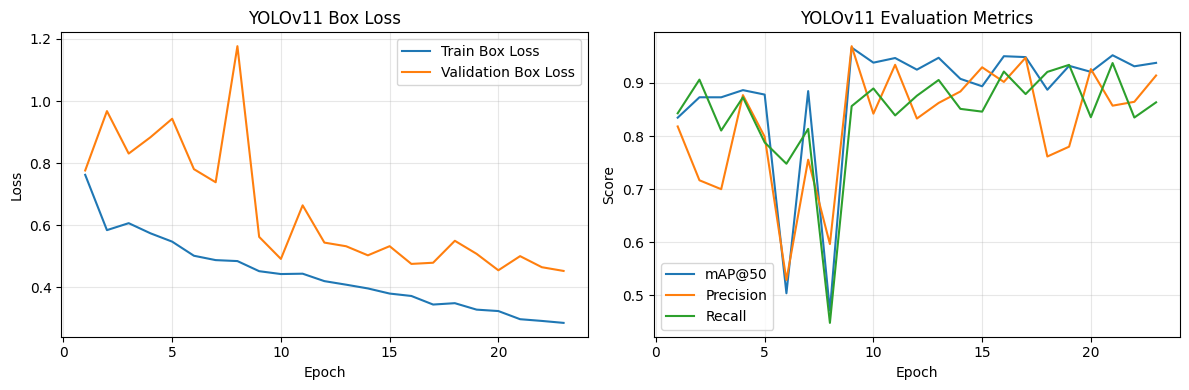

Best mAP@50: 0.9666


In [12]:
results_csv = YOLO_BEST.parent.parent / 'results.csv'

if not results_csv.exists():
    results_csv = OUTPUT_DIR / 'yolov11' / 'thorax' / 'results.csv'

if results_csv.exists():

    # load CSV hasil training
    df_yolo = pd.read_csv(results_csv)

    # menghilangkan spasi pada nama kolom
    df_yolo.columns = df_yolo.columns.str.strip()

    plt.figure(figsize=(12, 4))

    # ---------------------------------
    # SUBPLOT 1 : Loss
    # ---------------------------------
    plt.subplot(1, 2, 1)

    plt.plot(
        df_yolo['epoch'],
        df_yolo['train/box_loss'],
        label='Train Box Loss'
    )

    plt.plot(
        df_yolo['epoch'],
        df_yolo['val/box_loss'],
        label='Validation Box Loss'
    )

    plt.title('YOLOv11 Box Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(alpha=0.3)

    # ---------------------------------
    # SUBPLOT 2 : mAP50
    # ---------------------------------
    plt.subplot(1, 2, 2)

    plt.plot(
        df_yolo['epoch'],
        df_yolo['metrics/mAP50(B)'],
        label='mAP@50'
    )

    plt.plot(
        df_yolo['epoch'],
        df_yolo['metrics/precision(B)'],
        label='Precision'
    )

    plt.plot(
        df_yolo['epoch'],
        df_yolo['metrics/recall(B)'],
        label='Recall'
    )

    plt.title('YOLOv11 Evaluation Metrics')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    # simpan
    plt.savefig(
        OUTPUT_DIR / 'simple_yolov11_curves.png',
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()

    print(f'Best mAP@50: {df_yolo["metrics/mAP50(B)"].max():.4f}')

else:
    print('results.csv tidak ditemukan.')

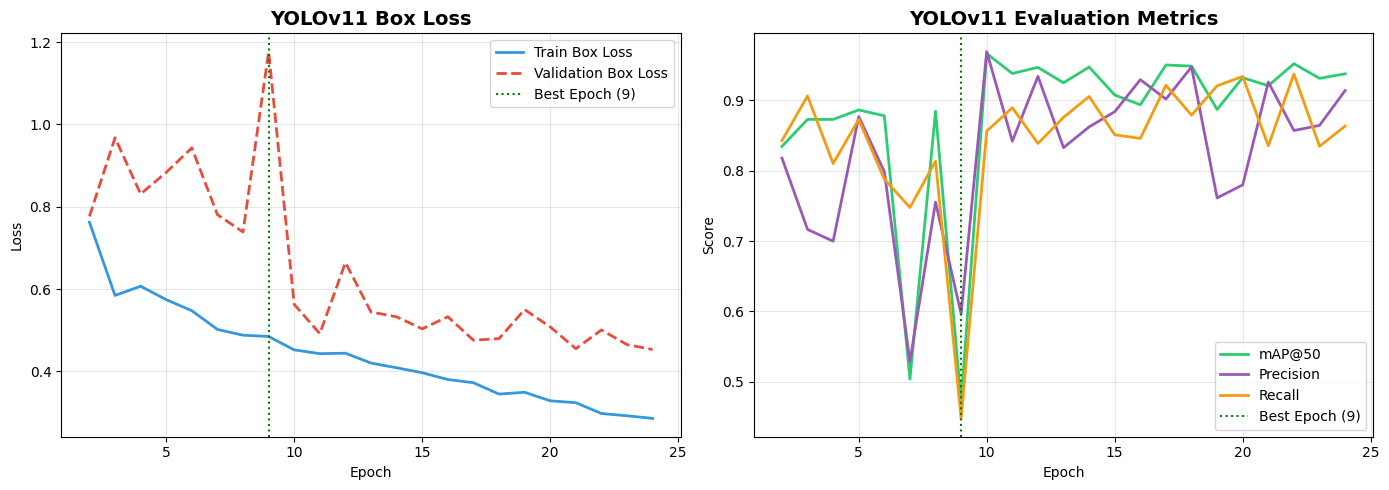

Best Epoch : 9
Best mAP@50: 0.9666
Disimpan   : outputs/yolov11_training_curves.png


In [13]:
results_csv = YOLO_BEST.parent.parent / 'results.csv'

if not results_csv.exists():
    results_csv = OUTPUT_DIR / 'yolo11' / 'thorax' / 'results.csv'

if results_csv.exists():

    # load csv
    df_yolo = pd.read_csv(results_csv)

    # hilangkan spasi nama kolom
    df_yolo.columns = df_yolo.columns.str.strip()


    epochs_r = df_yolo['epoch'] + 1

    train_loss = df_yolo['train/box_loss']
    val_loss   = df_yolo['val/box_loss']

    map50      = df_yolo['metrics/mAP50(B)']
    precision  = df_yolo['metrics/precision(B)']
    recall     = df_yolo['metrics/recall(B)']

    # best epoch berdasarkan mAP50 tertinggi
    best_ep = int(map50.idxmax()) + 1

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    ax[0].plot(
        epochs_r,
        train_loss,
        label='Train Box Loss',
        color='#3498DB',
        linewidth=2
    )

    ax[0].plot(
        epochs_r,
        val_loss,
        label='Validation Box Loss',
        color='#E74C3C',
        linewidth=2,
        linestyle='--'
    )

    # garis best epoch
    ax[0].axvline(
        x=best_ep,
        color='green',
        linestyle=':',
        linewidth=1.5,
        label=f'Best Epoch ({best_ep})'
    )

    ax[0].set_title(
        'YOLOv11 Box Loss',
        fontsize=14,
        fontweight='bold'
    )

    ax[0].set_xlabel('Epoch')
    ax[0].set_ylabel('Loss')
    ax[0].legend()
    ax[0].grid(alpha=0.3)

    ax[1].plot(
        epochs_r,
        map50,
        label='mAP@50',
        color='#2ECC71',
        linewidth=2
    )

    ax[1].plot(
        epochs_r,
        precision,
        label='Precision',
        color='#9B59B6',
        linewidth=2
    )

    ax[1].plot(
        epochs_r,
        recall,
        label='Recall',
        color='#F39C12',
        linewidth=2
    )

    # garis best epoch
    ax[1].axvline(
        x=best_ep,
        color='green',
        linestyle=':',
        linewidth=1.5,
        label=f'Best Epoch ({best_ep})'
    )

    ax[1].set_title(
        'YOLOv11 Evaluation Metrics',
        fontsize=14,
        fontweight='bold'
    )

    ax[1].set_xlabel('Epoch')
    ax[1].set_ylabel('Score')
    ax[1].legend()
    ax[1].grid(alpha=0.3)


    plt.tight_layout()

    save_path = OUTPUT_DIR / 'yolov11_training_curves.png'

    plt.savefig(
        save_path,
        dpi=150,
        bbox_inches='tight'
    )

    plt.show()

    print(f'Best Epoch : {best_ep}')
    print(f'Best mAP@50: {map50.max():.4f}')
    print(f'Disimpan   : {save_path}')

else:
    print('results.csv tidak ditemukan.')

In [14]:
from ultralytics import YOLO as YOLO_eval

yolo_eval_model = YOLO_eval(str(YOLO_BEST))

print('Evaluasi YOLOv11 pada Test Set...')
t0 = time.perf_counter()
yolo_metrics = yolo_eval_model.val(
    data=str(DATA_YAML.resolve()),
    split='test',
    device='mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'),
    verbose=True
)
yolo_infer_time = (time.perf_counter() - t0) / len(test_data) * 1000  # ms/img

yolo_map50     = float(yolo_metrics.box.map50)
yolo_map50_95  = float(yolo_metrics.box.map)
yolo_precision = float(yolo_metrics.box.mp)
yolo_recall    = float(yolo_metrics.box.mr)
yolo_f1        = 2 * yolo_precision * yolo_recall / (yolo_precision + yolo_recall + 1e-8)

# Per-kelas
yolo_per_class = {}
for i, cls_name in enumerate(CLASS_NAMES):
    yolo_per_class[cls_name] = {
        'precision': float(yolo_metrics.box.p[i]) if len(yolo_metrics.box.p) > i else 0.0,
        'recall':    float(yolo_metrics.box.r[i]) if len(yolo_metrics.box.r) > i else 0.0,
        'mAP50':     float(yolo_metrics.box.ap50[i]) if len(yolo_metrics.box.ap50) > i else 0.0,
    }

print('\nYOLOv11 Test Metrics:')
print(f'  mAP@50     : {yolo_map50:.4f}')
print(f'  mAP@50-95  : {yolo_map50_95:.4f}')
print(f'  Precision  : {yolo_precision:.4f}')
print(f'  Recall     : {yolo_recall:.4f}')
print(f'  F1 Score   : {yolo_f1:.4f}')
print(f'  Inf Time   : ~{yolo_infer_time:.1f} ms/gambar')
print('\n  Per Kelas:')
for k, v in yolo_per_class.items():
    print(f'    {k:15s}: P={v["precision"]:.4f} | R={v["recall"]:.4f} | mAP50={v["mAP50"]:.4f}')

Evaluasi YOLOv11 pada Test Set...
Ultralytics 8.4.14 🚀 Python-3.10.12 torch-2.10.0 MPS (Apple M4)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 96.8±31.3 MB/s, size: 18.4 KB)
val: Scanning /Users/mochammadirsyadkurniawan/UMB - Materi & Tugas/semester 8/yolo11/dataset/test/labels... 91 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 91/91 3.5Kit/s 0.0s
val: New cache created: /Users/mochammadirsyadkurniawan/UMB - Materi & Tugas/semester 8/yolo11/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.0it/s 5.7s0.6ss
                   all         91         91      0.699      0.858      0.799      0.729
          kardiomegali         44         44      0.544       0.76       0.64      0.565
                normal         47         47      0.854      0.957      0.958      0.893
Speed: 0.2ms preprocess, 40.6ms infe

Running YOLOv11 predictions on test set...


100%|██████████| 91/91 [00:02<00:00, 37.69it/s]



Detailed results saved to: outputs/yolo11_test_results.csv
Total gambar dievaluasi : 91
No Detection (YOLO11) : 2 gambar

Accuracy Model YOLO11 : 92.13%


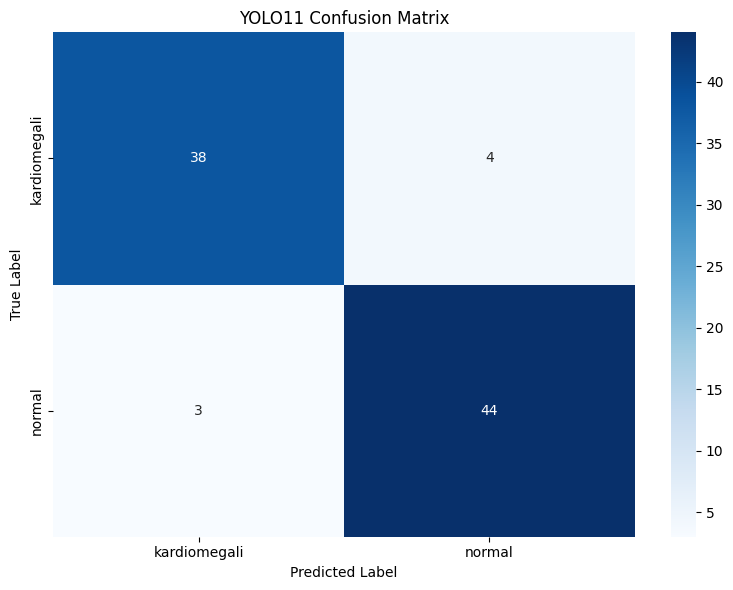

Confusion matrix saved to: outputs/yolo11_confusion_matrix.png

YOLO11 CLASSIFICATION REPORT
              precision    recall  f1-score   support

kardiomegali     0.9268    0.8636    0.8941        44
      normal     0.9167    0.9362    0.9263        47

   micro avg     0.9213    0.9011    0.9111        91
   macro avg     0.9217    0.8999    0.9102        91
weighted avg     0.9216    0.9011    0.9107        91



In [17]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

from tqdm import tqdm
from ultralytics import YOLO

model_yolo11 = YOLO(str(YOLO_BEST))

test_images_dir = TEST_IMG
test_labels_dir = TEST_LBL

test_image_files = sorted(
    list(test_images_dir.glob('*'))
)

print("Running YOLOv11 predictions on test set...")

# storage
y_true = []
y_pred = []
y_scores = []

detailed_results = []

# PREDICTION LOOP
for img_path in tqdm(test_image_files):

    label_path = (
        test_labels_dir
        / f'{img_path.stem}.txt'
    )

    if label_path.exists():

        # GROUND TRUTH
        with open(label_path, 'r') as f:
            gt_lines = f.readlines()

        # skip empty label
        if len(gt_lines) > 0:

            gt_class = int(
                gt_lines[0].split()[0]
            )

            y_true.append(gt_class)

            # PREDICT
            results = model_yolo11.predict(
                source=str(img_path),

                conf=0.5,
                iou=0.5,

                device=DEVICE,

                verbose=False
            )

            # IF DETECTION EXISTS
            if len(results[0].boxes) > 0:

                confidences = (
                    results[0]
                    .boxes
                    .conf
                    .cpu()
                    .numpy()
                )

                classes = (
                    results[0]
                    .boxes
                    .cls
                    .cpu()
                    .numpy()
                    .astype(int)
                )

                # ambil confidence tertinggi
                best_idx = confidences.argmax()

                pred_class = int(
                    classes[best_idx]
                )

                pred_conf = float(
                    confidences[best_idx]
                )

                y_pred.append(pred_class)
                y_scores.append(pred_conf)

            else:
                # no detection
                y_pred.append(-1)
                y_scores.append(0.0)

            pred_label_idx = y_pred[-1]

            detailed_results.append({

                'image':
                    img_path.name,

                'true_class':
                    CLASS_NAMES[gt_class],

                'pred_class':
                    (
                        CLASS_NAMES[pred_label_idx]
                        if pred_label_idx != -1
                        else 'No Detection'
                    ),

                'confidence':
                    y_scores[-1],

                'correct':
                    gt_class == pred_label_idx
            })


df_results = pd.DataFrame(
    detailed_results
)

csv_path = (
    OUTPUT_DIR
    / 'yolo11_test_results.csv'
)

df_results.to_csv(
    csv_path,
    index=False
)

print(
    f'\nDetailed results saved to: {csv_path}'
)

print(
    f'Total gambar dievaluasi : {len(y_true)}'
)

no_det_yolo11 = y_pred.count(-1)

print(
    f'No Detection (YOLO11) : '
    f'{no_det_yolo11} gambar'
)

detected_mask = [
    p != -1
    for p in y_pred
]

y_true_det = [
    y_true[i]
    for i in range(len(detected_mask))
    if detected_mask[i]
]

y_pred_det = [
    y_pred[i]
    for i in range(len(detected_mask))
    if detected_mask[i]
]

# accuracy
accuracy_det = (
    accuracy_score(
        y_true_det,
        y_pred_det
    )
    if y_true_det
    else 0.0
)

print(
    f'\nAccuracy Model YOLO11 : '
    f'{accuracy_det * 100:.2f}%'
)

# CONFUSION MATRIX
cm = confusion_matrix(
    y_true_det,
    y_pred_det
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,

    annot=True,
    fmt='d',

    cmap='Blues',

    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title('YOLO11 Confusion Matrix')

plt.xlabel('Predicted Label')

plt.ylabel('True Label')

plt.tight_layout()

cm_path = (
    OUTPUT_DIR
    / 'yolo11_confusion_matrix.png'
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(
    f'Confusion matrix saved to: {cm_path}'
)

# CLASSIFICATION REPORT
print('\n' + '=' * 60)

print('YOLO11 CLASSIFICATION REPORT')

print('=' * 60)

labels_for_report = list(
    range(len(CLASS_NAMES))
)

print(
    classification_report(
        y_true,
        y_pred,

        labels=labels_for_report,

        target_names=CLASS_NAMES,

        digits=4,

        zero_division=0
    )
)

print('=' * 60)

In [18]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

class ThoraxDatasetSSD(Dataset):
    def __init__(self, img_dir, lbl_dir, img_size=300, augment=False):
        self.img_dir   = Path(img_dir)
        self.lbl_dir   = Path(lbl_dir)
        self.img_size  = img_size
        self.augment   = augment
        self.img_files = sorted(
            list(self.img_dir.glob('*.jpg')) +
            list(self.img_dir.glob('*.jpeg')) +
            list(self.img_dir.glob('*.png'))
        )
        self.aug_transform  = self._build_aug()
        self.base_transform = self._build_base()

    # Augmentasi (hanya dipakai saat train)
    def _build_aug(self):
        return A.Compose([
            A.ShiftScaleRotate(
                shift_limit=0.05, scale_limit=0.10,
                rotate_limit=5,
                border_mode=cv2.BORDER_CONSTANT, value=0, p=0.6
            ),
            A.RandomBrightnessContrast(
                brightness_limit=0.20, contrast_limit=0.20, p=0.5
            ),
            A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.4),
            A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
        ], bbox_params=A.BboxParams(
            format='pascal_voc',          # [x1,y1,x2,y2] absolut
            label_fields=['class_labels'],
            min_visibility=0.3,           # buang box yang nyaris hilang
            clip=True
        ))
 
    # Base (resize + normalize, selalu dipakai) 
    def _build_base(self):
        return A.Compose([
            A.Resize(self.img_size, self.img_size),
            A.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225]),
            ToTensorV2()
        ], bbox_params=A.BboxParams(
            format='pascal_voc',
            label_fields=['class_labels'],
            min_visibility=0.3,
            clip=True
        ))

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_path = self.img_files[idx]
        lbl_path = self.lbl_dir / (img_path.stem + '.txt')

        # load image sebagai numpy array (albumentations butuh HWC uint8)
        img = np.array(Image.open(img_path).convert('RGB'))
        H, W = img.shape[:2]

        boxes, labels = [], []
        if lbl_path.exists():
            for line in lbl_path.read_text().strip().splitlines():
                p = line.strip().split()
                if len(p) == 5:
                    cls_id = int(p[0])
                    cx, cy, bw, bh = map(float, p[1:])
                    # YOLO (normalised) → pascal_voc (absolut px, resolusi asli)
                    x1 = (cx - bw / 2) * W
                    y1 = (cy - bh / 2) * H
                    x2 = (cx + bw / 2) * W
                    y2 = (cy + bh / 2) * H
                    x1 = max(0.0, min(x1, W))
                    y1 = max(0.0, min(y1, H))
                    x2 = max(0.0, min(x2, W))
                    y2 = max(0.0, min(y2, H))
                    if x2 - x1 >= 2 and y2 - y1 >= 2:   # skip degenerate
                        boxes.append([x1, y1, x2, y2])
                        labels.append(cls_id + 1)         # 0=bg → 1=kardiomegali, 2=normal

        # augmentasi (pada resolusi asli, sebelum resize)
        if self.augment and boxes:
            try:
                out   = self.aug_transform(image=img, bboxes=boxes,
                                           class_labels=labels)
                img   = out['image']
                boxes = list(out['bboxes'])
                labels = list(out['class_labels'])
            except Exception:
                pass   # fallback ke gambar tanpa augmentasi

        # base transform (resize + normalize + ToTensor)
        if boxes:
            out    = self.base_transform(image=img, bboxes=boxes,
                                         class_labels=labels)
            img_t  = out['image']           # (3, S, S) float32 tensor
            boxes  = out['bboxes']
            labels = out['class_labels']
        else:
            out    = self.base_transform(image=img, bboxes=[],
                                         class_labels=[])
            img_t  = out['image']

        if boxes:
            boxes_t  = torch.tensor(list(boxes),  dtype=torch.float32)
            labels_t = torch.tensor(list(labels), dtype=torch.int64)
        else:
            boxes_t  = torch.zeros((0, 4), dtype=torch.float32)
            labels_t = torch.zeros((0,),   dtype=torch.int64)

        target = {'boxes': boxes_t, 'labels': labels_t}
        return img_t, target


def collate_fn(batch):
    return tuple(zip(*batch))


train_ds_ssd = ThoraxDatasetSSD(TRAIN_IMG, TRAIN_LBL, SSD_SIZE, augment=True)
valid_ds_ssd = ThoraxDatasetSSD(VALID_IMG, VALID_LBL, SSD_SIZE, augment=False)
test_ds_ssd  = ThoraxDatasetSSD(TEST_IMG,  TEST_LBL,  SSD_SIZE, augment=False)

train_loader_ssd = DataLoader(train_ds_ssd, batch_size=8,  shuffle=True,
                               collate_fn=collate_fn, num_workers=0, pin_memory=False)
valid_loader_ssd = DataLoader(valid_ds_ssd, batch_size=8,  shuffle=False,
                               collate_fn=collate_fn, num_workers=0, pin_memory=False)
test_loader_ssd  = DataLoader(test_ds_ssd,  batch_size=4,  shuffle=False,
                               collate_fn=collate_fn, num_workers=0, pin_memory=False)

print(f'Dataset SSD — Train: {len(train_ds_ssd)} | Valid: {len(valid_ds_ssd)} | Test: {len(test_ds_ssd)}')

img_t, tgt = train_ds_ssd[0]
print(f'   img_t shape : {img_t.shape}  dtype={img_t.dtype}')
print(f'   Boxes       : {tgt["boxes"][:2]}')
print(f'   Labels      : {tgt["labels"][:2]}  (1=kardiomegali, 2=normal)')
assert img_t.shape == (3, SSD_SIZE, SSD_SIZE), 'Shape salah!'

Dataset SSD — Train: 1280 | Valid: 92 | Test: 91
   img_t shape : torch.Size([3, 300, 300])  dtype=torch.float32
   Boxes       : tensor([[  0.0000,   8.2131, 296.9913, 285.9686]])
   Labels      : tensor([2])  (1=kardiomegali, 2=normal)


In [19]:
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead

def build_ssd_model(num_classes=NUM_CLASSES, score_thresh=0.01, nms_thresh=0.45):
    model = ssd300_vgg16(
        weights=SSD300_VGG16_Weights.DEFAULT,
        score_thresh=score_thresh,   # threshold pada saat inference
        nms_thresh=nms_thresh,
        detections_per_img=10        # cukup untuk 1 objek per gambar X-ray
    )
    in_channels = [512, 1024, 512, 256, 256, 256]
    num_anchors = model.anchor_generator.num_anchors_per_location()
    # Ganti classification head dengan jumlah kelas yang sesuai
    model.head.classification_head = SSDClassificationHead(
        in_channels=in_channels,
        num_anchors=num_anchors,
        num_classes=num_classes      # NUM_CLASSES = 3 (bg + kardiomegali + normal)
    )
    return model


def freeze_backbone(model, freeze_up_to=10):
    """Freeze n layer pertama VGG backbone untuk stabilkan feature pretrained."""
    for i, (name, param) in enumerate(model.backbone.named_parameters()):
        if i < freeze_up_to:
            param.requires_grad = False

def unfreeze_backbone(model):
    """Unfreeze semua parameter untuk fine-tuning penuh."""
    for param in model.backbone.parameters():
        param.requires_grad = True

ssd_model = build_ssd_model().to(DEVICE)
freeze_backbone(ssd_model, freeze_up_to=10)   # freeze awal

n_total   = sum(p.numel() for p in ssd_model.parameters())
n_trained = sum(p.numel() for p in ssd_model.parameters() if p.requires_grad)
print(f'SSD Model — Total params  : {n_total:,}')
print(f'            Trainable     : {n_trained:,}  (backbone sebagian difreeze)')

SSD Model — Total params  : 23,879,570
            Trainable     : 23,323,986  (backbone sebagian difreeze)


In [20]:
torch.set_num_threads(4)

# Hyperparameter 
SSD_EPOCHS        = 25          
SSD_WARMUP_EPOCHS = 3           # epoch warmup dengan backbone freeze
SSD_LR            = 5e-3        # SGD LR awal (setelah warmup)
SSD_LR_WARMUP     = 5e-4        # SGD LR saat warmup
SSD_MOMENTUM      = 0.9
SSD_WEIGHT_DECAY  = 5e-4       
ACCUM_STEPS       = 2           # gradient accumulation → effective batch=16
PATIENCE          = 7           # early stopping
SSD_CKPT          = OUTPUT_DIR / 'ssd_best.pt'

# optimizer SGD — lebih baik untuk fine-tuning SSD pretrained
optimizer_ssd = optim.SGD(
    filter(lambda p: p.requires_grad, ssd_model.parameters()),
    lr=SSD_LR_WARMUP,           # mulai dengan LR kecil saat warmup
    momentum=SSD_MOMENTUM,
    weight_decay=SSD_WEIGHT_DECAY,
    nesterov=True
)

# diaktifkan setelah warmup selesai
def make_main_scheduler(opt, milestones, gamma=0.1):
    return optim.lr_scheduler.MultiStepLR(opt, milestones=milestones, gamma=gamma)

ssd_train_losses = []
ssd_val_losses   = []
best_val_loss    = float('inf')
no_improve_count = 0

# ── Training loop helpers ──────────────────────────────────────────────────────
def train_one_epoch_ssd(model, loader, optimizer, device, accum_steps=2):
    model.train()
    total_loss = 0.0
    optimizer.zero_grad()
    pbar = tqdm(loader, desc='  Train', leave=False)
    
    for step, (imgs, targets) in enumerate(pbar):
        imgs    = [img.to(device) for img in imgs]
        targets = [{'boxes': t['boxes'].to(device),
                    'labels': t['labels'].to(device)} for t in targets]
        loss_dict = model(imgs, targets)
        loss = sum(loss_dict.values()) / accum_steps
        loss.backward()
        
        if (step + 1) % accum_steps == 0 or (step + 1) == len(loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            optimizer.zero_grad()

        total_loss += loss.item() * accum_steps
        pbar.set_postfix({
            'loss': f'{loss.item() * accum_steps:.4f}',
            'lr':   f'{optimizer.param_groups[0]["lr"]:.5f}'
        })
    return total_loss / len(loader)

@torch.no_grad()
def eval_loss_ssd(model, loader, device):
    # SSD torchvision butuh mode train() untuk menghitung loss
    model.train()
    total_loss = 0.0
    pbar = tqdm(loader, desc='  Valid', leave=False)
    for imgs, targets in pbar:
        imgs    = [img.to(device) for img in imgs]
        targets = [{'boxes': t['boxes'].to(device),
                    'labels': t['labels'].to(device)} for t in targets]
        loss_dict = model(imgs, targets)
        loss = sum(loss_dict.values())
        total_loss += loss.item()
        pbar.set_postfix({'val_loss': f'{loss.item():.4f}'})
    return total_loss / len(loader)

# training loop 
print('Training SSD300 — Best Practice Config')
print(f'  Epochs        : {SSD_EPOCHS} (max, dengan early stopping)')
print(f'  Warmup epochs : {SSD_WARMUP_EPOCHS} (backbone freeze)')
print(f'  Optimizer     : SGD  lr={SSD_LR_WARMUP} → {SSD_LR}')
print(f'  Accum steps   : {ACCUM_STEPS} (effective batch = {8 * ACCUM_STEPS})')
print(f'  Early stop    : patience={PATIENCE}')

main_scheduler = None  # diinisialisasi setelah warmup

for epoch in range(1, SSD_EPOCHS + 1):
    print(f'\nEpoch {epoch}/{SSD_EPOCHS}')

    # Fase warmup: backbone freeze, LR kecil
    if epoch == 1:
        print('  [Warmup] Backbone difreeze sebagian, LR kecil')

    # Setelah warmup: unfreeze backbone, naikkan LR, aktifkan scheduler 
    if epoch == SSD_WARMUP_EPOCHS + 1:
        print('  [Unfreeze] Backbone penuh di-unfreeze, LR dinaikkan')
        unfreeze_backbone(ssd_model)
        # Update optimizer dengan semua parameter
        optimizer_ssd = optim.SGD(
            ssd_model.parameters(),
            lr=SSD_LR,
            momentum=SSD_MOMENTUM,
            weight_decay=SSD_WEIGHT_DECAY,
            nesterov=True
        )

        remaining = SSD_EPOCHS - SSD_WARMUP_EPOCHS
        m1 = SSD_WARMUP_EPOCHS + int(remaining * 0.5)
        m2 = SSD_WARMUP_EPOCHS + int(remaining * 0.8)
        main_scheduler = make_main_scheduler(optimizer_ssd, milestones=[m1, m2])
        print(f'  Scheduler milestones: epoch {m1} dan {m2}')

    train_loss = train_one_epoch_ssd(ssd_model, train_loader_ssd,
                                     optimizer_ssd, DEVICE, ACCUM_STEPS)
    val_loss   = eval_loss_ssd(ssd_model, valid_loader_ssd, DEVICE)

    if main_scheduler is not None:
        main_scheduler.step()

    ssd_train_losses.append(train_loss)
    ssd_val_losses.append(val_loss)

    save_flag = ''
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        no_improve_count = 0
        torch.save(ssd_model.state_dict(), SSD_CKPT)
        save_flag = '⭐ Best Saved'
    else:
        no_improve_count += 1

    cur_lr = optimizer_ssd.param_groups[0]['lr']
    print(f'  Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | '
          f'LR: {cur_lr:.6f} | No-improve: {no_improve_count}/{PATIENCE} {save_flag}')

    # early stopping
    if no_improve_count >= PATIENCE and epoch > SSD_WARMUP_EPOCHS + 5:
        print(f'\n  Early stopping triggered di epoch {epoch}.')
        break

print(f'\nSSD Training selesai — Best Val Loss: {best_val_loss:.4f}')
print(f'  Model tersimpan di: {SSD_CKPT}')

Training SSD300 — Best Practice Config
  Epochs        : 25 (max, dengan early stopping)
  Warmup epochs : 3 (backbone freeze)
  Optimizer     : SGD  lr=0.0005 → 0.005
  Accum steps   : 2 (effective batch = 16)
  Early stop    : patience=7

Epoch 1/25
  [Warmup] Backbone difreeze sebagian, LR kecil


  Train Loss: 6.5749 | Val Loss: 3.2773 | LR: 0.000500 | No-improve: 0/7 ⭐ Best Saved

Epoch 2/25


  Train Loss: 2.7932 | Val Loss: 2.2087 | LR: 0.000500 | No-improve: 0/7 ⭐ Best Saved

Epoch 3/25


  Train Loss: 2.2142 | Val Loss: 1.7917 | LR: 0.000500 | No-improve: 0/7 ⭐ Best Saved

Epoch 4/25
  [Unfreeze] Backbone penuh di-unfreeze, LR dinaikkan
  Scheduler milestones: epoch 14 dan 20


  Train Loss: 1.9792 | Val Loss: 1.1431 | LR: 0.005000 | No-improve: 0/7 ⭐ Best Saved

Epoch 5/25


  Train Loss: 1.3355 | Val Loss: 1.7605 | LR: 0.005000 | No-improve: 1/7 

Epoch 6/25


... (12 outputs left out)

  Train Loss: 0.4143 | Val Loss: 0.8278 | LR: 0.000500 | No-improve: 4/7 

Epoch 19/25


  Train Loss: 0.3597 | Val Loss: 0.8317 | LR: 0.000500 | No-improve: 5/7 

Epoch 20/25


  Train Loss: 0.3340 | Val Loss: 0.8323 | LR: 0.000500 | No-improve: 6/7 

Epoch 21/25


  Train Loss: 0.3121 | Val Loss: 0.8030 | LR: 0.000500 | No-improve: 7/7 

  Early stopping triggered di epoch 21.

SSD Training selesai — Best Val Loss: 0.7221
  Model tersimpan di: outputs/ssd_best.pt


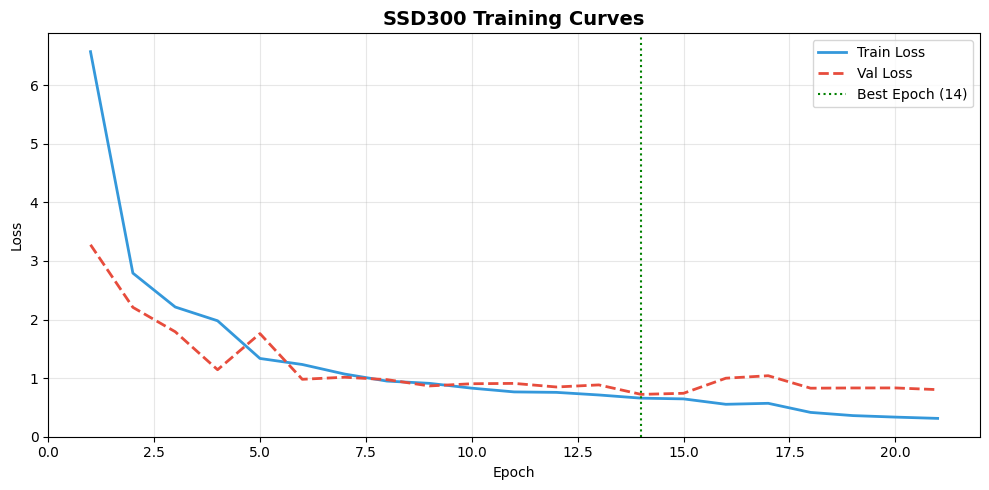

disimpan: outputs/ssd_training_curves.png


In [21]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
epochs_r = range(1, len(ssd_train_losses) + 1)
ax.plot(epochs_r, ssd_train_losses, label='Train Loss', color='#3498DB', linewidth=2)
ax.plot(epochs_r, ssd_val_losses,   label='Val Loss',   color='#E74C3C', linewidth=2, linestyle='--')
best_ep = int(np.argmin(ssd_val_losses)) + 1
ax.axvline(x=best_ep, color='green', linestyle=':', linewidth=1.5, label=f'Best Epoch ({best_ep})')
ax.set_title('SSD300 Training Curves', fontsize=14, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ssd_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('disimpan: outputs/ssd_training_curves.png')

In [22]:
try:
    from torchmetrics.detection.mean_ap import MeanAveragePrecision
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'torchmetrics', '-q'])
    from torchmetrics.detection.mean_ap import MeanAveragePrecision

# load best model
ssd_model.load_state_dict(torch.load(SSD_CKPT, map_location=DEVICE, weights_only=True))
ssd_model.eval().to(DEVICE)

CONF_THRESH = 0.5
IOU_THRESH  = 0.5

metric_map = MeanAveragePrecision(iou_type='bbox', class_metrics=True)

# kumpulkan prediksi untuk perhitungan Precision/Recall manual
all_preds_pr  = []   # list of dicts: {'boxes', 'scores', 'labels'}
all_targets_pr = []  # list of dicts: {'boxes', 'labels'}

print('Evaluasi SSD pada Test Set...')
t0 = time.perf_counter()

with torch.no_grad():
    for imgs, targets in tqdm(test_loader_ssd, desc='SSD Eval'):
        imgs = [img.to(DEVICE) for img in imgs]
        preds = ssd_model(imgs)

        for pred, tgt in zip(preds, targets):
            # Filter by confidence threshold
            keep = pred['scores'] >= CONF_THRESH
            filtered_pred = {
                'boxes':  pred['boxes'][keep].cpu(),
                'scores': pred['scores'][keep].cpu(),
                'labels': pred['labels'][keep].cpu(),
            }
            tgt_cpu = {
                'boxes':  tgt['boxes'].cpu(),
                'labels': tgt['labels'].cpu(),
            }
            all_preds_pr.append(filtered_pred)
            all_targets_pr.append(tgt_cpu)

        # torchmetrics butuh semua prediksi (tanpa filter conf)
        preds_cpu   = [{'boxes': p['boxes'].cpu(), 'scores': p['scores'].cpu(),
                        'labels': p['labels'].cpu()} for p in preds]
        targets_cpu = [{'boxes': t['boxes'].cpu(), 'labels': t['labels'].cpu()}
                       for t in targets]
        metric_map.update(preds_cpu, targets_cpu)

ssd_infer_time = (time.perf_counter() - t0) / len(test_ds_ssd) * 1000  # ms/img

ssd_map_results = metric_map.compute()
ssd_map50    = float(ssd_map_results['map_50'])
ssd_map50_95 = float(ssd_map_results['map'])


# ── Hitung Precision & Recall per kelas (IoU=0.5, conf≥0.5) ─────────────────
def compute_pr_per_class(all_preds, all_targets, num_fg_classes, iou_threshold=0.5):
    """
    Hitung Precision dan Recall per kelas menggunakan IoU matching.
    num_fg_classes: jumlah kelas foreground (tanpa background).
                    Label SSD: 1=kardiomegali, 2=normal → num_fg_classes=2
    """
    stats = {c: {'TP': 0, 'FP': 0, 'FN': 0} for c in range(1, num_fg_classes + 1)}

    for pred, tgt in zip(all_preds, all_targets):
        pred_boxes  = pred['boxes']    # (N, 4)
        pred_labels = pred['labels']   # (N,)
        gt_boxes    = tgt['boxes']     # (M, 4)
        gt_labels   = tgt['labels']   # (M,)

        matched_gt = set()

        for i in range(len(pred_boxes)):
            pb  = pred_boxes[i]
            pcl = pred_labels[i].item()

            if pcl not in stats:
                continue

            best_iou, best_j = 0.0, -1
            for j in range(len(gt_boxes)):
                if gt_labels[j].item() != pcl or j in matched_gt:
                    continue
                iou = box_iou_single(pb, gt_boxes[j])
                if iou > best_iou:
                    best_iou, best_j = iou, j

            if best_iou >= iou_threshold and best_j >= 0:
                stats[pcl]['TP'] += 1
                matched_gt.add(best_j)
            else:
                stats[pcl]['FP'] += 1

        for j in range(len(gt_boxes)):
            if j not in matched_gt:
                gcl = gt_labels[j].item()
                if gcl in stats:
                    stats[gcl]['FN'] += 1

    precision_per_class, recall_per_class = {}, {}
    for c in range(1, num_fg_classes + 1):
        tp, fp, fn = stats[c]['TP'], stats[c]['FP'], stats[c]['FN']
        precision_per_class[c] = tp / (tp + fp + 1e-8)
        recall_per_class[c]    = tp / (tp + fn + 1e-8)

    return precision_per_class, recall_per_class


def box_iou_single(boxA, boxB):
    xA = max(boxA[0], boxB[0]); yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2]); yB = min(boxA[3], boxB[3])
    inter = max(0, xB - xA) * max(0, yB - yA)
    areaA = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    areaB = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    return inter / (areaA + areaB - inter + 1e-8)


ssd_precision_cls, ssd_recall_cls = compute_pr_per_class(
    all_preds_pr, all_targets_pr, num_fg_classes=2, iou_threshold=IOU_THRESH
)

# rata-rata macro precision & recall
ssd_precision = np.mean(list(ssd_precision_cls.values()))
ssd_recall    = np.mean(list(ssd_recall_cls.values()))
ssd_f1        = 2 * ssd_precision * ssd_recall / (ssd_precision + ssd_recall + 1e-8)

# per-kelas mAP dari torchmetrics
ssd_per_class = {}
if 'map_per_class' in ssd_map_results:
    for i, cls_name in enumerate(CLASS_NAMES):
        ssd_per_class[cls_name] = {
            'precision': ssd_precision_cls.get(i + 1, 0.0),
            'recall':    ssd_recall_cls.get(i + 1, 0.0),
            'mAP50':     float(ssd_map_results['map_per_class'][i])
                         if i < len(ssd_map_results['map_per_class']) else 0.0,
        }

print('\nSSD Test Metrics:')
print(f'  mAP@50     : {ssd_map50:.4f}')
print(f'  mAP@50-95  : {ssd_map50_95:.4f}')
print(f'  Precision  : {ssd_precision:.4f}  (IoU=0.5, conf≥{CONF_THRESH})')
print(f'  Recall     : {ssd_recall:.4f}')
print(f'  F1 Score   : {ssd_f1:.4f}')
print(f'  Inf Time   : ~{ssd_infer_time:.1f} ms/gambar')
print('\n  Per Kelas:')
for k, v in ssd_per_class.items():
    print(f'    {k:15s}: P={v["precision"]:.4f} | R={v["recall"]:.4f} | mAP50={v["mAP50"]:.4f}')

Evaluasi SSD pada Test Set...


SSD Eval: 100%|██████████| 23/23 [00:07<00:00,  3.21it/s]


SSD Test Metrics:
  mAP@50     : 0.9057
  mAP@50-95  : 0.7357
  Precision  : 0.8765  (IoU=0.5, conf≥0.5)
  Recall     : 0.8765
  F1 Score   : 0.8765
  Inf Time   : ~78.8 ms/gambar

  Per Kelas:
    kardiomegali   : P=0.7955 | R=0.7955 | mAP50=0.5988
    normal         : P=0.9574 | R=0.9574 | mAP50=0.8725


Running SSD predictions on test set...


100%|██████████| 23/23 [00:03<00:00,  5.87it/s]



Detailed results saved to: outputs/ssd_test_results.csv
Total gambar dievaluasi : 91
No Detection (SSD)     : 3 gambar

Accuracy Model SSD : 95.45%


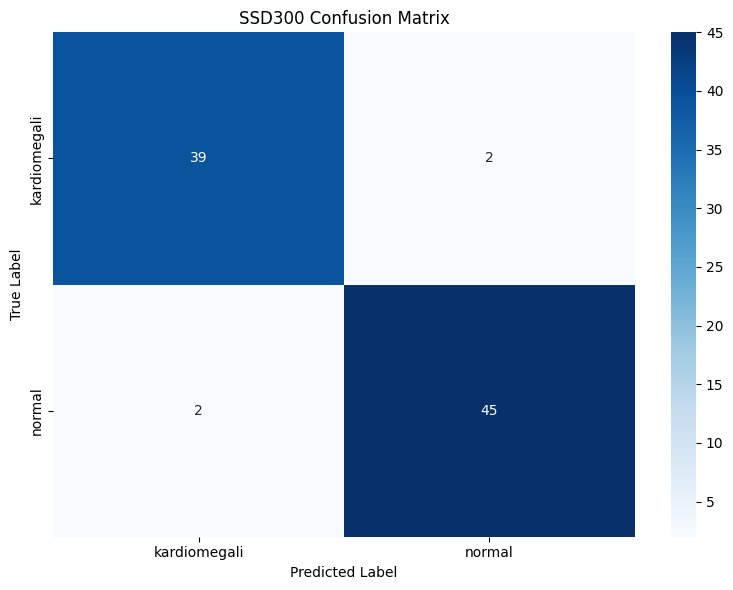

Confusion matrix saved to: outputs/ssd_confusion_matrix.png

SSD300 CLASSIFICATION REPORT

              precision    recall  f1-score   support

kardiomegali     0.9512    0.8864    0.9176        44
      normal     0.9574    0.9574    0.9574        47

   micro avg     0.9545    0.9231    0.9385        91
   macro avg     0.9543    0.9219    0.9375        91
weighted avg     0.9544    0.9231    0.9382        91



In [23]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import torch

ssd_model.load_state_dict(
    torch.load(SSD_CKPT, map_location=DEVICE, weights_only=True)
)

ssd_model.eval().to(DEVICE)

print("Running SSD predictions on test set...")

y_true = []
y_pred = []
y_scores = []
detailed_results = []

with torch.no_grad():

    for imgs, targets in tqdm(test_loader_ssd):

        imgs = [img.to(DEVICE) for img in imgs]

        predictions = ssd_model(imgs)

        for pred, target in zip(predictions, targets):

            if len(target['labels']) > 0:

                gt_class = int(target['labels'][0].item()) - 1
                y_true.append(gt_class)

            else:
                continue


            keep = pred['scores'] >= 0.5

            boxes  = pred['boxes'][keep]
            scores = pred['scores'][keep]
            labels = pred['labels'][keep]

            if len(scores) > 0:

                best_idx = scores.argmax()

                pred_class = int(labels[best_idx].item()) - 1
                pred_conf  = float(scores[best_idx].item())

                y_pred.append(pred_class)
                y_scores.append(pred_conf)

            else:

                y_pred.append(-1)
                y_scores.append(0.0)

            pred_label_idx = y_pred[-1]

            detailed_results.append({
                'true_class': CLASS_NAMES[y_true[-1]],
                'pred_class': CLASS_NAMES[pred_label_idx] if pred_label_idx != -1 else 'No Detection',
                'confidence': y_scores[-1],
                'correct': y_true[-1] == pred_label_idx
            })

df_results = pd.DataFrame(detailed_results)

csv_path = OUTPUT_DIR / 'ssd_test_results.csv'

df_results.to_csv(csv_path, index=False)

print(f'\nDetailed results saved to: {csv_path}')
print(f'Total gambar dievaluasi : {len(y_true)}')

no_det_ssd = y_pred.count(-1)

print(f'No Detection (SSD)     : {no_det_ssd} gambar')

y_true_filtered = y_true
y_pred_filtered = y_pred

# accuracy hanya untuk gambar yang berhasil terdeteksi
detected_mask = [p != -1 for p in y_pred_filtered]

y_true_det = [
    y_true_filtered[i]
    for i in range(len(detected_mask))
    if detected_mask[i]
]

y_pred_det = [
    y_pred_filtered[i]
    for i in range(len(detected_mask))
    if detected_mask[i]
]

accuracy_det = accuracy_score(y_true_det, y_pred_det) if y_true_det else 0.0

print(f'\nAccuracy Model SSD : {accuracy_det * 100:.2f}%')

cm = confusion_matrix(y_true_det, y_pred_det)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title('SSD300 Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.tight_layout()

cm_path = OUTPUT_DIR / 'ssd_confusion_matrix.png'

plt.savefig(cm_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'Confusion matrix saved to: {cm_path}')

print('\n' + '='*60)
print('SSD300 CLASSIFICATION REPORT')
print('='*60)

print()

# hanya class asli
labels_for_report = list(range(len(CLASS_NAMES)))

print(
    classification_report(
        y_true_filtered,
        y_pred_filtered,
        labels=labels_for_report,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

print('='*60)

In [25]:
import time
import torch
from ultralytics import YOLO

model_yolo11 = YOLO(str(YOLO_BEST))

print('Evaluasi ulang YOLO11 pada Test Set...')

t0 = time.perf_counter()

yolo11_metrics = model_yolo11.val(
    data=str(DATA_YAML.resolve()),
    split='test',

    device='mps'
    if torch.backends.mps.is_available()
    else (
        'cuda'
        if torch.cuda.is_available()
        else 'cpu'
    ),

    verbose=False
)

yolo11_map50 = float(yolo11_metrics.box.map50)

yolo11_map50_95 = float(yolo11_metrics.box.map)

yolo11_precision = float(yolo11_metrics.box.mp)

yolo11_recall = float(yolo11_metrics.box.mr)

yolo11_f1 = (
    2
    * yolo11_precision
    * yolo11_recall
    / (
        yolo11_precision
        + yolo11_recall
        + 1e-8
    )
)

yolo11_infer_time = (
    (time.perf_counter() - t0)
    / len(test_data)
    * 1000
)

print('\nYOLO11 metrics.')

print(f'mAP50     : {yolo11_map50:.4f}')
print(f'mAP50-95  : {yolo11_map50_95:.4f}')
print(f'Precision : {yolo11_precision:.4f}')
print(f'Recall    : {yolo11_recall:.4f}')
print(f'F1 Score  : {yolo11_f1:.4f}')

Evaluasi ulang YOLO11 pada Test Set...
Ultralytics 8.4.14 🚀 Python-3.10.12 torch-2.10.0 MPS (Apple M4)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 11.7±3.7 MB/s, size: 17.4 KB)
val: Scanning /Users/mochammadirsyadkurniawan/UMB - Materi & Tugas/semester 8/yolo11/dataset/test/labels.cache... 91 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 91/91 6.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.3it/s 2.6s0.5ss
                   all         91         91      0.699      0.858      0.799      0.729
Speed: 0.2ms preprocess, 12.6ms inference, 0.0ms loss, 6.1ms postprocess per image
Results saved to /Users/mochammadirsyadkurniawan/UMB - Materi & Tugas/semester 8/yolo11/runs/detect/val2

YOLO11 metrics.
mAP50     : 0.7990
mAP50-95  : 0.7287
Precision : 0.6991
Recall    : 0.8585
F1 Score  : 0.7706



----------------------------------------------------------------------
TABEL PERBANDINGAN AKHIR
----------------------------------------------------------------------
       Model  mAP@50  mAP@50-95  Precision  Recall  F1 Score  Inf (ms)
     YOLO11s  0.7990     0.7287     0.6991  0.8585    0.7706     43.98
SSD300-VGG16  0.9057     0.7357     0.8765  0.8765    0.8765     78.76

CSV saved: outputs/comparison_results.csv


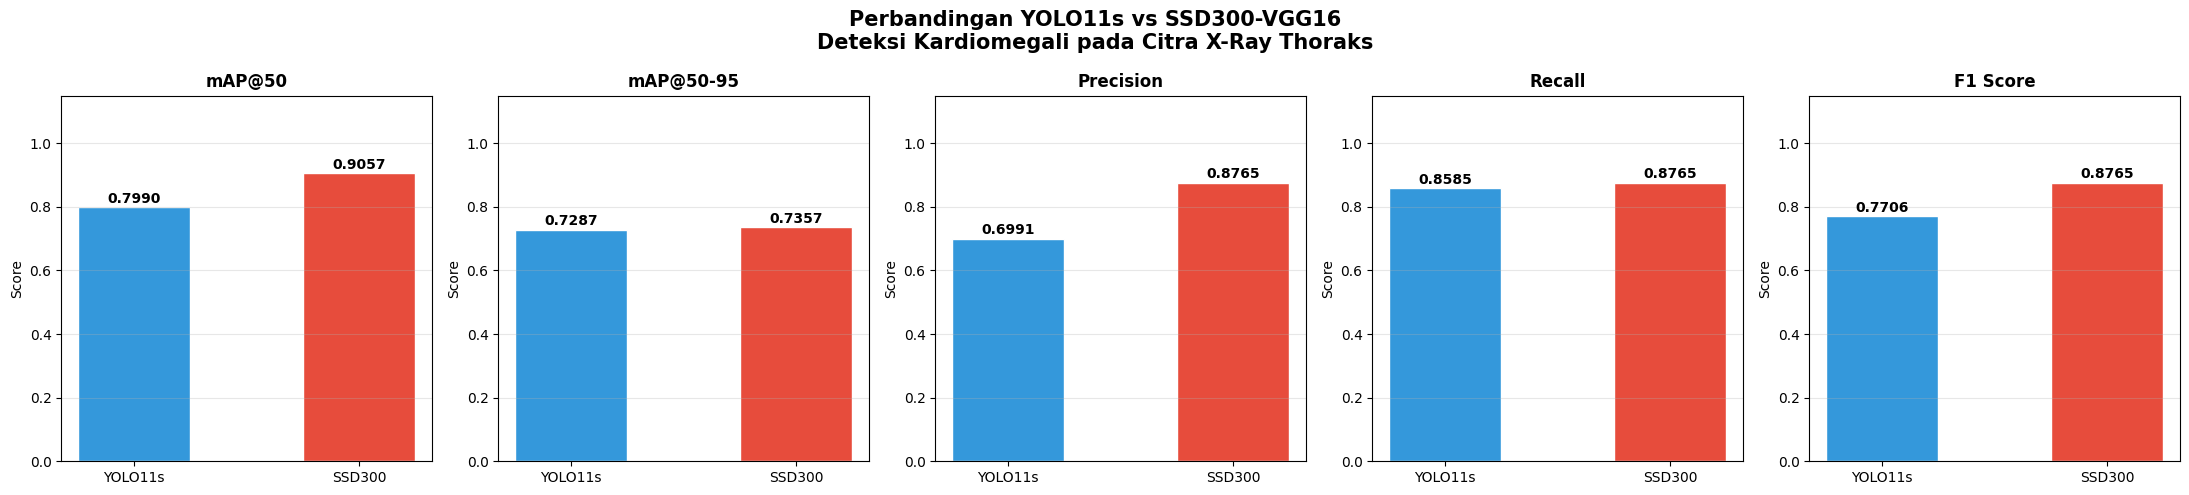

Chart saved : outputs/comparison_chart.png
CSV saved   : outputs/comparison_results.csv


In [26]:
import pandas as pd
import matplotlib.pyplot as plt

comparison_df = pd.DataFrame({

    'Model': [
        'YOLO11s',
        'SSD300-VGG16'
    ],

    'mAP@50': [
        round(yolo11_map50, 4),
        round(ssd_map50, 4)
    ],

    'mAP@50-95': [
        round(yolo11_map50_95, 4),
        round(ssd_map50_95, 4)
    ],

    'Precision': [
        round(yolo11_precision, 4),
        round(ssd_precision, 4)
    ],

    'Recall': [
        round(yolo11_recall, 4),
        round(ssd_recall, 4)
    ],

    'F1 Score': [
        round(yolo11_f1, 4),
        round(ssd_f1, 4)
    ],

    'Inf (ms)': [
        round(yolo11_infer_time, 2),
        round(ssd_infer_time, 2)
    ],
})

print('\n' + '-' * 70)

print('TABEL PERBANDINGAN AKHIR')

print('-' * 70)

print(
    comparison_df.to_string(index=False)
)

csv_save_path = (
    OUTPUT_DIR
    / 'comparison_results.csv'
)

comparison_df.to_csv(
    csv_save_path,
    index=False
)

print(f'\nCSV saved: {csv_save_path}')

metric_cols = [

    'mAP@50',

    'mAP@50-95',

    'Precision',

    'Recall',

    'F1 Score'
]

fig, axes = plt.subplots(
    1,
    len(metric_cols),

    figsize=(22, 5)
)

fig.suptitle(

    'Perbandingan YOLO11s vs SSD300-VGG16\n'
    'Deteksi Kardiomegali pada Citra X-Ray Thoraks',

    fontsize=15,
    fontweight='bold'
)

bar_colors = [

    '#3498DB',   # biru YOLO11

    '#E74C3C'    # merah SSD
]

model_labels = [

    'YOLO11s',

    'SSD300'
]


for ax, col in zip(axes, metric_cols):

    vals = comparison_df[col].tolist()

    bars = ax.bar(

        model_labels,

        vals,

        color=bar_colors,

        edgecolor='white',

        width=0.5
    )

    for bar, val in zip(bars, vals):

        ax.text(

            bar.get_x() + bar.get_width() / 2,

            bar.get_height() + 0.005,

            f'{val:.4f}',

            ha='center',

            va='bottom',

            fontweight='bold',

            fontsize=10
        )

    ax.set_title(
        col,
        fontsize=12,
        fontweight='bold'
    )

    ax.set_ylim(0, 1.15)

    ax.set_ylabel('Score')

    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()

chart_save_path = (
    OUTPUT_DIR
    / 'comparison_chart.png'
)

plt.savefig(

    chart_save_path,

    dpi=150,

    bbox_inches='tight'
)

plt.show()
print(f'Chart saved : {chart_save_path}')

print(f'CSV saved   : {csv_save_path}')

TABEL PERBANDINGAN MODEL: YOLO11s vs SSD300
                 Metrik  YOLO11s  SSD300 (VGG16)  Unggul
                 mAP@50   0.7990          0.9057  SSD300
              mAP@50-95   0.7287          0.7357  SSD300
              Precision   0.6991          0.8765  SSD300
                 Recall   0.8585          0.8765  SSD300
               F1-Score   0.7706          0.8765  SSD300
Inference Time (ms/img)  43.9800         78.7600 YOLO11s
      Ukuran Model (MB)  18.2700         91.1200 YOLO11s

Tabel disimpan ke: outputs/model_comparison.csv


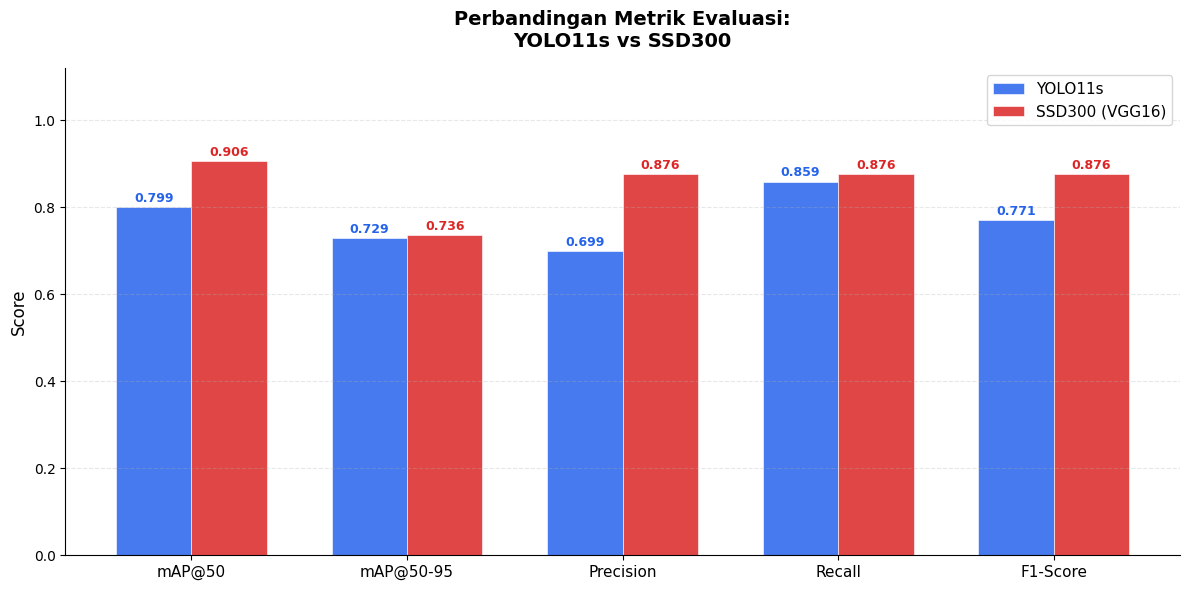

Chart disimpan ke: outputs/model_comparison_chart.png


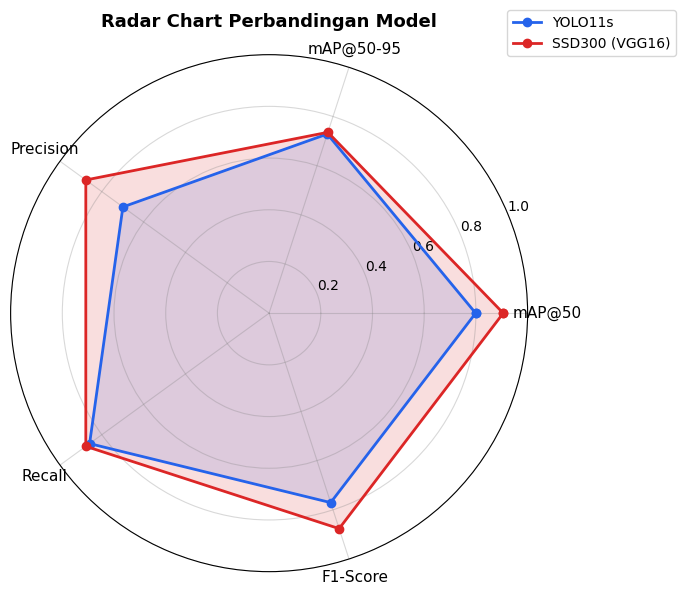

Radar chart disimpan ke: outputs/model_comparison_radar.png

----------------------------------------------------------------------
KESIMPULAN PERBANDINGAN
----------------------------------------------------------------------
YOLO11s unggul pada : 2 metrik
SSD300 unggul pada  : 5 metrik

SSD300 lebih baik di mAP@50 sebesar 10.66 poin
YOLO11s lebih cepat (44.0 ms vs 78.8 ms/gambar)


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

def get_model_size_mb(path):

    try:
        return round(
            os.path.getsize(path)
            / (1024 * 1024),
            2
        )

    except FileNotFoundError:
        return None

yolo11_size_mb = get_model_size_mb(
    str(YOLO_BEST)
)

ssd_size_mb = get_model_size_mb(
    str(SSD_CKPT)
)

comparison_data = {

    'Metrik': [

        'mAP@50',

        'mAP@50-95',

        'Precision',

        'Recall',

        'F1-Score',

        'Inference Time (ms/img)',

        'Ukuran Model (MB)'
    ],

    'YOLO11s': [

        round(yolo11_map50, 4),

        round(yolo11_map50_95, 4),

        round(yolo11_precision, 4),

        round(yolo11_recall, 4),

        round(yolo11_f1, 4),

        round(yolo11_infer_time, 2),

        yolo11_size_mb
        if yolo11_size_mb
        else 'N/A',
    ],

    'SSD300 (VGG16)': [

        round(ssd_map50, 4),

        round(ssd_map50_95, 4),

        round(ssd_precision, 4),

        round(ssd_recall, 4),

        round(ssd_f1, 4),

        round(ssd_infer_time, 2),

        ssd_size_mb
        if ssd_size_mb
        else 'N/A',
    ],
}


df_comp = pd.DataFrame(
    comparison_data
)

higher_is_better = [

    True,   # mAP50

    True,   # mAP50-95

    True,   # Precision

    True,   # Recall

    True,   # F1

    False,  # inference time

    False   # model size
]

winners = []

for i, hib in enumerate(higher_is_better):

    row_yolo11 = comparison_data['YOLO11s'][i]

    row_ssd = comparison_data['SSD300 (VGG16)'][i]

    # skip string
    if isinstance(row_yolo11, str) or isinstance(row_ssd, str):

        winners.append('-')

    elif hib:

        winners.append(
            'YOLO11s'
            if row_yolo11 >= row_ssd
            else 'SSD300'
        )

    else:

        winners.append(
            'YOLO11s'
            if row_yolo11 <= row_ssd
            else 'SSD300'
        )

df_comp['Unggul'] = winners

print('=' * 70)

print(
    'TABEL PERBANDINGAN MODEL: '
    'YOLO11s vs SSD300'
)

print('=' * 70)

print(
    df_comp.to_string(index=False)
)

print('=' * 70)

csv_path = (
    OUTPUT_DIR
    / 'model_comparison.csv'
)

df_comp.to_csv(
    csv_path,
    index=False
)

print(f'\nTabel disimpan ke: {csv_path}')

metrics_plot = [

    'mAP@50',

    'mAP@50-95',

    'Precision',

    'Recall',

    'F1-Score'
]

yolo11_vals = [
    comparison_data['YOLO11s'][i]
    for i in range(5)
]

ssd_vals = [
    comparison_data['SSD300 (VGG16)'][i]
    for i in range(5)
]

x = np.arange(len(metrics_plot))

width = 0.35

fig, ax = plt.subplots(
    figsize=(12, 6)
)

bars_yolo11 = ax.bar(

    x - width / 2,

    yolo11_vals,

    width,

    label='YOLO11s',

    color='#2563EB',

    alpha=0.85,

    edgecolor='white',

    linewidth=0.5
)

bars_ssd = ax.bar(

    x + width / 2,

    ssd_vals,

    width,

    label='SSD300 (VGG16)',

    color='#DC2626',

    alpha=0.85,

    edgecolor='white',

    linewidth=0.5
)

for bar in bars_yolo11:

    h = bar.get_height()

    ax.text(

        bar.get_x() + bar.get_width() / 2,

        h + 0.005,

        f'{h:.3f}',

        ha='center',

        va='bottom',

        fontsize=9,

        color='#2563EB',

        fontweight='bold'
    )

for bar in bars_ssd:

    h = bar.get_height()

    ax.text(

        bar.get_x() + bar.get_width() / 2,

        h + 0.005,

        f'{h:.3f}',

        ha='center',

        va='bottom',

        fontsize=9,

        color='#DC2626',

        fontweight='bold'
    )

ax.set_title(

    'Perbandingan Metrik Evaluasi:\n'
    'YOLO11s vs SSD300',

    fontsize=14,

    fontweight='bold',

    pad=15
)

ax.set_xticks(x)

ax.set_xticklabels(
    metrics_plot,
    fontsize=11
)

ax.set_ylabel(
    'Score',
    fontsize=12
)

ax.set_ylim(0, 1.12)

ax.legend(fontsize=11)

ax.grid(
    axis='y',
    alpha=0.3,
    linestyle='--'
)

ax.spines['top'].set_visible(False)

ax.spines['right'].set_visible(False)

plt.tight_layout()

chart_path = (
    OUTPUT_DIR
    / 'model_comparison_chart.png'
)

plt.savefig(

    chart_path,

    dpi=150,

    bbox_inches='tight'
)

plt.show()

print(f'Chart disimpan ke: {chart_path}')

labels_radar = metrics_plot

num_vars = len(labels_radar)

angles = np.linspace(
    0,
    2 * np.pi,
    num_vars,
    endpoint=False
).tolist()

angles += angles[:1]

# close radar
yolo11_r = yolo11_vals + [yolo11_vals[0]]

ssd_r = ssd_vals + [ssd_vals[0]]

fig2, ax2 = plt.subplots(

    figsize=(7, 7),

    subplot_kw=dict(polar=True)
)

ax2.plot(

    angles,

    yolo11_r,

    'o-',

    color='#2563EB',

    linewidth=2,

    label='YOLO11s'
)

ax2.fill(

    angles,

    yolo11_r,

    color='#2563EB',

    alpha=0.15
)

ax2.plot(

    angles,

    ssd_r,

    'o-',

    color='#DC2626',

    linewidth=2,

    label='SSD300 (VGG16)'
)

ax2.fill(

    angles,

    ssd_r,

    color='#DC2626',

    alpha=0.15
)

ax2.set_thetagrids(

    np.degrees(angles[:-1]),

    labels_radar,

    fontsize=11
)

ax2.set_ylim(0, 1)

ax2.set_title(

    'Radar Chart Perbandingan Model',

    fontsize=13,

    fontweight='bold',

    pad=20
)

ax2.legend(

    loc='upper right',

    bbox_to_anchor=(1.3, 1.1),

    fontsize=10
)

ax2.grid(
    color='gray',
    alpha=0.3
)

plt.tight_layout()

radar_path = (
    OUTPUT_DIR
    / 'model_comparison_radar.png'
)

plt.savefig(

    radar_path,

    dpi=150,

    bbox_inches='tight'
)

plt.show()

print(f'Radar chart disimpan ke: {radar_path}')

print('\n' + '-' * 70)

print('KESIMPULAN PERBANDINGAN')

print('-' * 70)

yolo11_wins = winners.count('YOLO11s')

ssd_wins = winners.count('SSD300')

print(
    f'YOLO11s unggul pada : '
    f'{yolo11_wins} metrik'
)

print(
    f'SSD300 unggul pada  : '
    f'{ssd_wins} metrik'
)

if yolo11_map50 > ssd_map50:

    diff = (
        yolo11_map50
        - ssd_map50
    ) * 100

    print(
        f'\nYOLO11s lebih baik '
        f'di mAP@50 sebesar '
        f'{diff:.2f} poin'
    )

else:

    diff = (
        ssd_map50
        - yolo11_map50
    ) * 100

    print(
        f'\nSSD300 lebih baik '
        f'di mAP@50 sebesar '
        f'{diff:.2f} poin'
    )

if yolo11_infer_time < ssd_infer_time:

    print(
        f'YOLO11s lebih cepat '
        f'({yolo11_infer_time:.1f} ms '
        f'vs '
        f'{ssd_infer_time:.1f} ms/gambar)'
    )

else:

    print(
        f'SSD300 lebih cepat '
        f'({ssd_infer_time:.1f} ms '
        f'vs '
        f'{yolo11_infer_time:.1f} ms/gambar)'
    )

print('=' * 70)

Running YOLO11 inference on sample test images...


Image 1/6
File: 802-MEHMOOD-TN-26-02-1980_PNG.rf.b799294de101c580dc20aa3287e37a3c.jpg


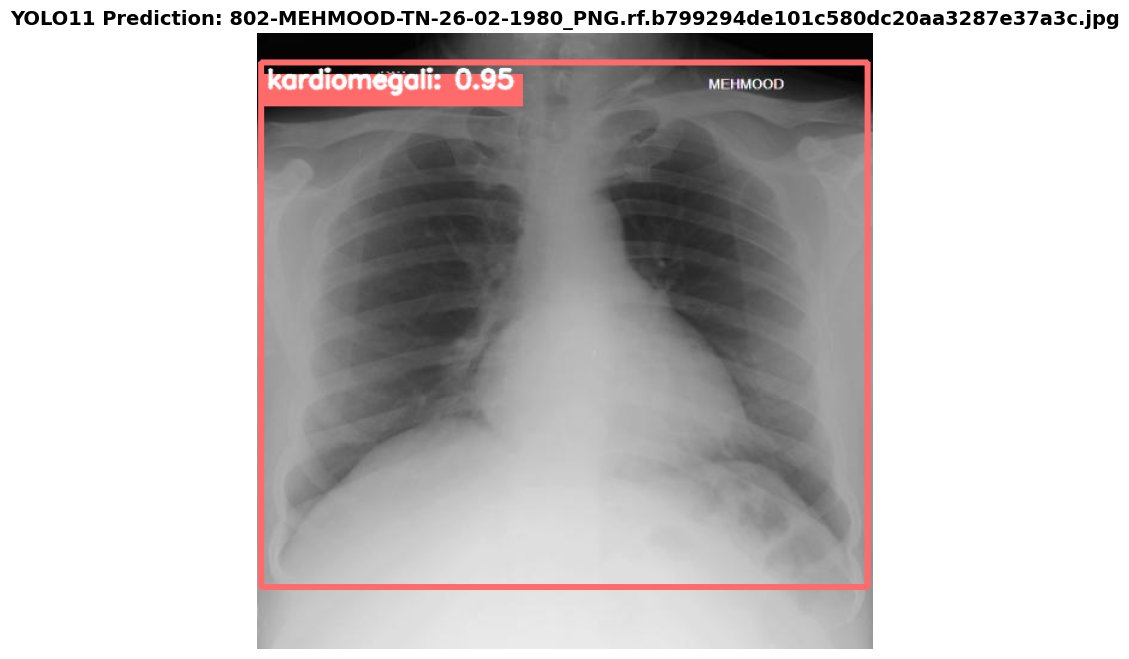

Saved to: outputs/yolo11_inference/yolo11_inference_1.png

Image 2/6
File: 27-AZMI-15-10-1982_PNG.rf.fa1250bb7dcc832fb82ee36710d2271a.jpg


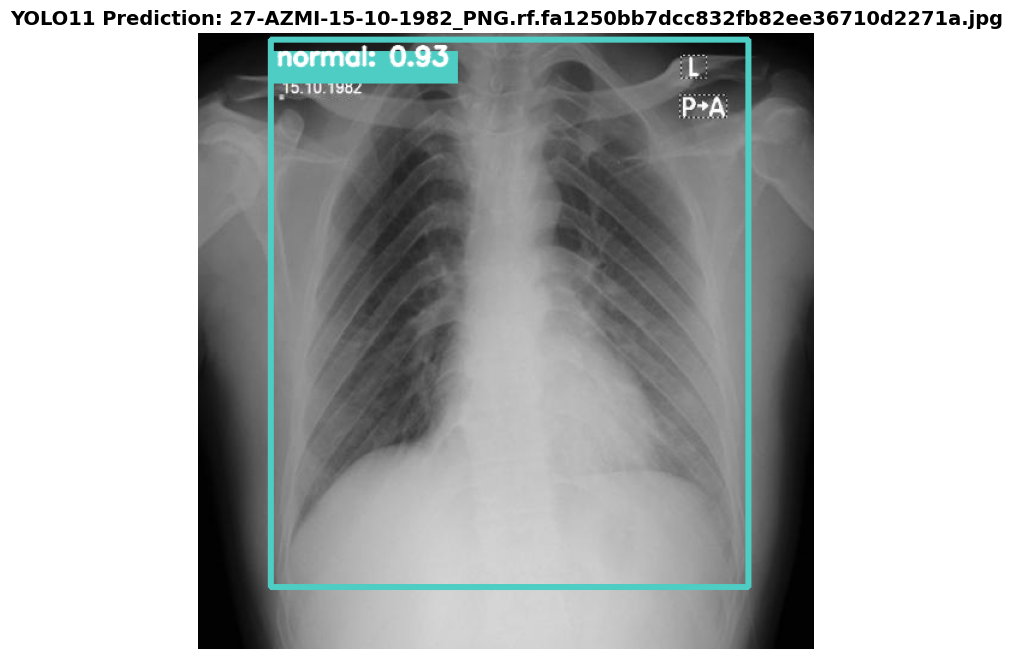

Saved to: outputs/yolo11_inference/yolo11_inference_2.png

Image 3/6
File: 28-ANONG-FACHRUDDIN_JPG.rf.e091bb03bb6fc5b9c35121fca73b4ac0.jpg


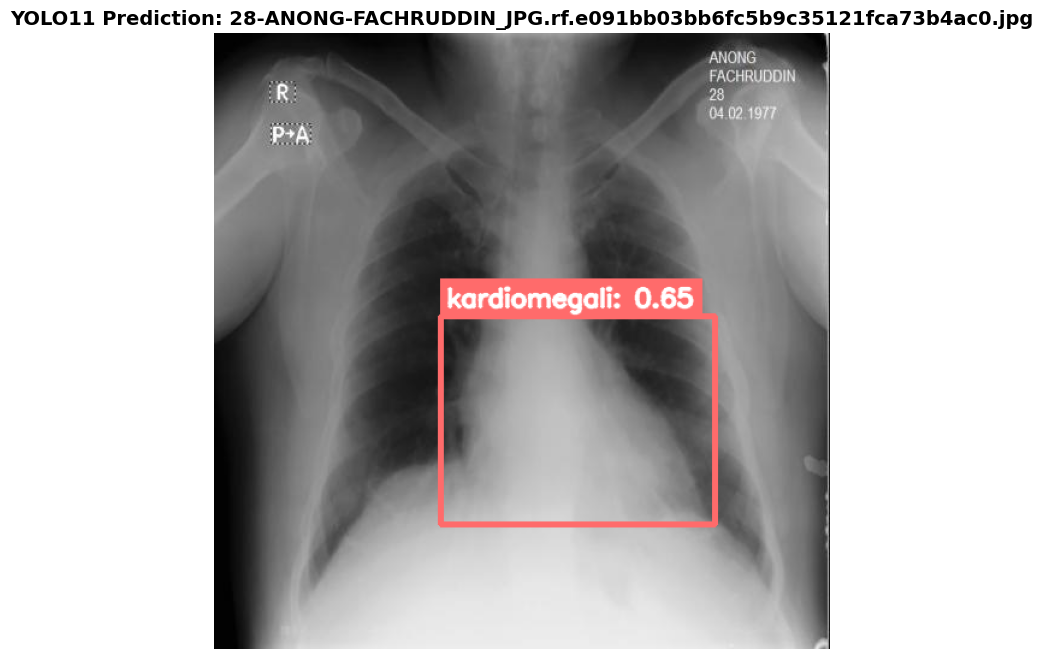

Saved to: outputs/yolo11_inference/yolo11_inference_3.png

Image 4/6
File: 558-ADE-SIF-TN-29-03-1988_PNG.rf.d1246ad851b7eb396f73bf76a15e3593.jpg


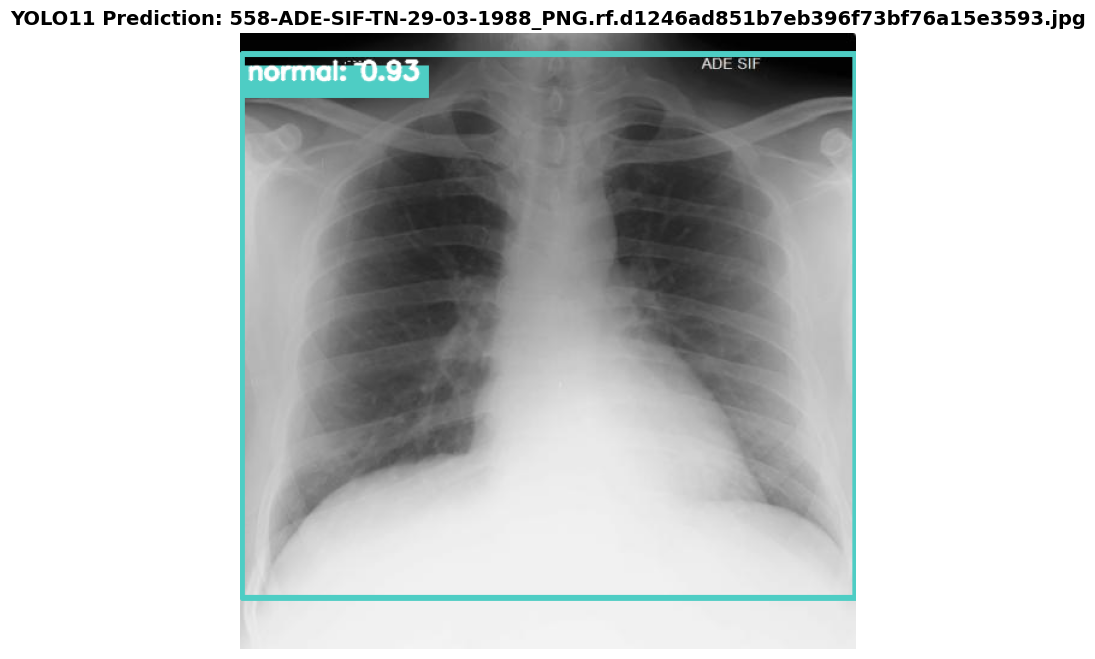

Saved to: outputs/yolo11_inference/yolo11_inference_4.png

Image 5/6
File: 26-PEBRIYANTI-SITUMORANG_JPG.rf.be04e88eafd59777797e68d2ab2b09f0.jpg


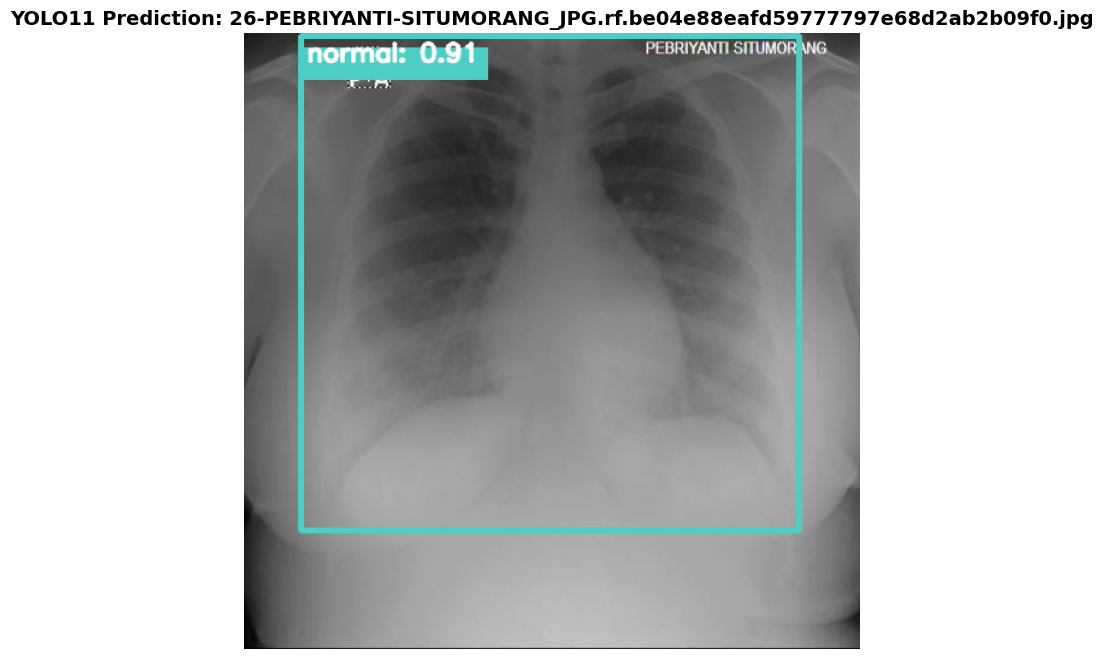

Saved to: outputs/yolo11_inference/yolo11_inference_5.png

Image 6/6
File: 524-EKI-DESRIZAL-TN-07-01-1991_PNG.rf.9d7cff15fdfd1f8d97ae3b7e6e85210b.jpg


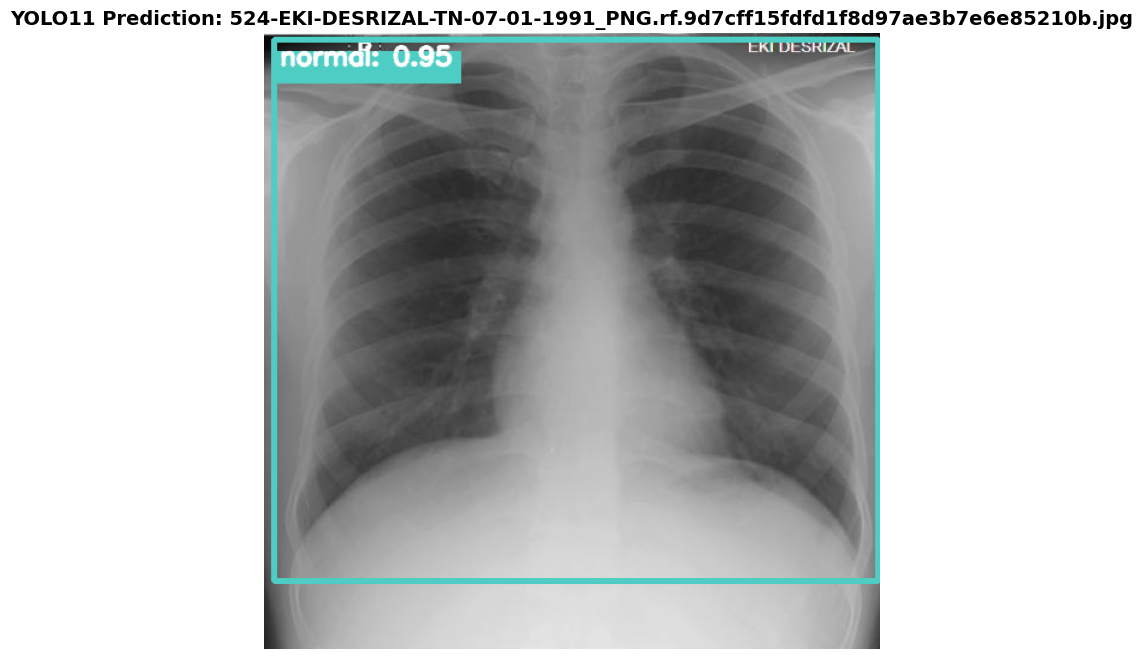

Saved to: outputs/yolo11_inference/yolo11_inference_6.png


In [30]:
import cv2
import random
import matplotlib.pyplot as plt

from ultralytics import YOLO

# load best YOLO11 model
model_yolo11 = YOLO(str(YOLO_BEST))

# output directory
INFERENCE_DIR = OUTPUT_DIR / 'yolo11_inference'
INFERENCE_DIR.mkdir(exist_ok=True)

# Color map
colors_map = {
    0: (255, 107, 107),   # kardiomegali
    1: (78, 205, 196)     # normal
}

# draw label
def draw_label(img, text, x1, y1, color):

    font = cv2.FONT_HERSHEY_SIMPLEX

    font_scale = 0.7

    thickness = 2

    text_size, _ = cv2.getTextSize(
        text,
        font,
        font_scale,
        thickness
    )

    text_w, text_h = text_size

    # jika terlalu atas → pindah ke bawah bbox
    if y1 - text_h - 15 < 0:

        label_y1 = y1 + 10
        label_y2 = y1 + text_h + 20

        text_y = y1 + text_h + 5

    else:

        label_y1 = y1 - text_h - 15
        label_y2 = y1

        text_y = y1 - 8

    # background label
    cv2.rectangle(

        img,

        (x1, label_y1),

        (x1 + text_w + 10, label_y2),

        color,

        -1
    )

    # text
    cv2.putText(

        img,

        text,

        (x1 + 5, text_y),

        font,

        font_scale,

        (255, 255, 255),

        thickness,

        cv2.LINE_AA
    )

# Inference function
def run_inference_and_visualize(
    image_path,
    save_path=None
):

    # predict
    results = model_yolo11.predict(

        source=str(image_path),

        conf=0.5,

        iou=0.5,

        device=DEVICE,

        verbose=False
    )

    # read image
    img = cv2.imread(str(image_path))

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    # draw prediction
    for result in results:

        boxes = result.boxes

        for box in boxes:

            x1, y1, x2, y2 = (
                box.xyxy[0]
                .cpu()
                .numpy()
                .astype(int)
            )

            conf = float(
                box.conf[0]
                .cpu()
                .numpy()
            )

            cls = int(
                box.cls[0]
                .cpu()
                .numpy()
            )

            color = colors_map[cls]

            # bbox
            cv2.rectangle(

                img,

                (x1, y1),

                (x2, y2),

                color,

                3
            )

            # label
            label = (
                f'{CLASS_NAMES[cls]}: '
                f'{conf:.2f}'
            )

            draw_label(
                img,
                label,
                x1,
                y1,
                color
            )

    # display
    plt.figure(figsize=(10, 8))

    plt.imshow(img)

    plt.axis('off')

    plt.title(

        f'YOLO11 Prediction: {image_path.name}',

        fontsize=14,

        fontweight='bold'
    )

    # save
    if save_path:

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches='tight'
        )

    plt.show()

    return results

# Sample images
test_image_files = sorted(
    list(TEST_IMG.glob('*'))
)

print('Running YOLO11 inference on sample test images...\n')

sample_test_images = random.sample(

    test_image_files,

    min(6, len(test_image_files))
)

for idx, img_path in enumerate(sample_test_images):

    print(f'\nImage {idx + 1}/{len(sample_test_images)}')

    print(f'File: {img_path.name}')

    save_path = (
        INFERENCE_DIR
        / f'yolo11_inference_{idx + 1}.png'
    )

    results = run_inference_and_visualize(
        img_path,
        save_path
    )

    print(f'Saved to: {save_path}')

Running SSD300 inference on sample test images...


Image 1/6
File: ADITYA-E-PUTRA_JPG.rf.ab59ba6ba7fd6225c7892f6ce7a4593e.jpg


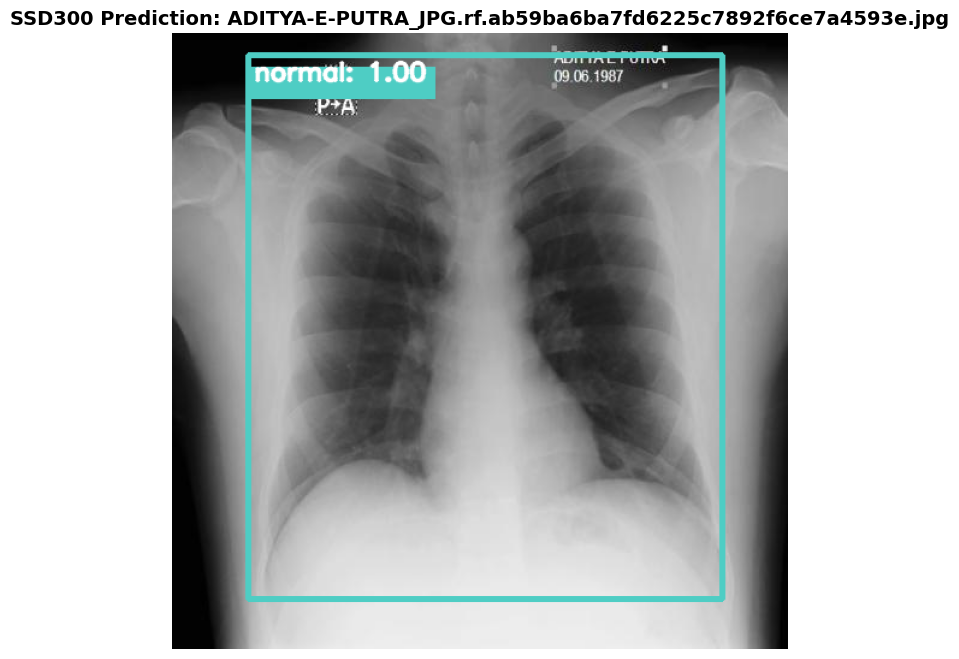

Saved to: outputs/ssd_inference/ssd_inference_1.png

Image 2/6
File: MUHAMMAD-NASRI-17-08-1976_JPG.rf.2052c093a992afcf06d3b4f713221ccf.jpg


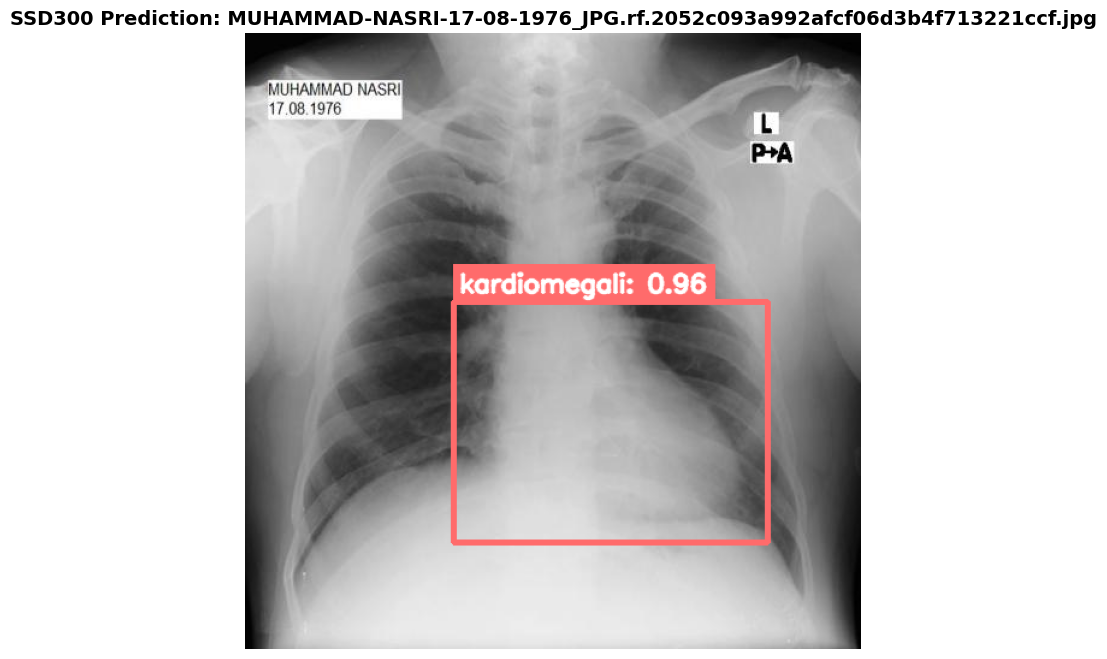

Saved to: outputs/ssd_inference/ssd_inference_2.png

Image 3/6
File: 04-HARLY-SYAHFRIL-10-12-1984_PNG.rf.fb2f3520aedc767924e53ac833a26b6d.jpg


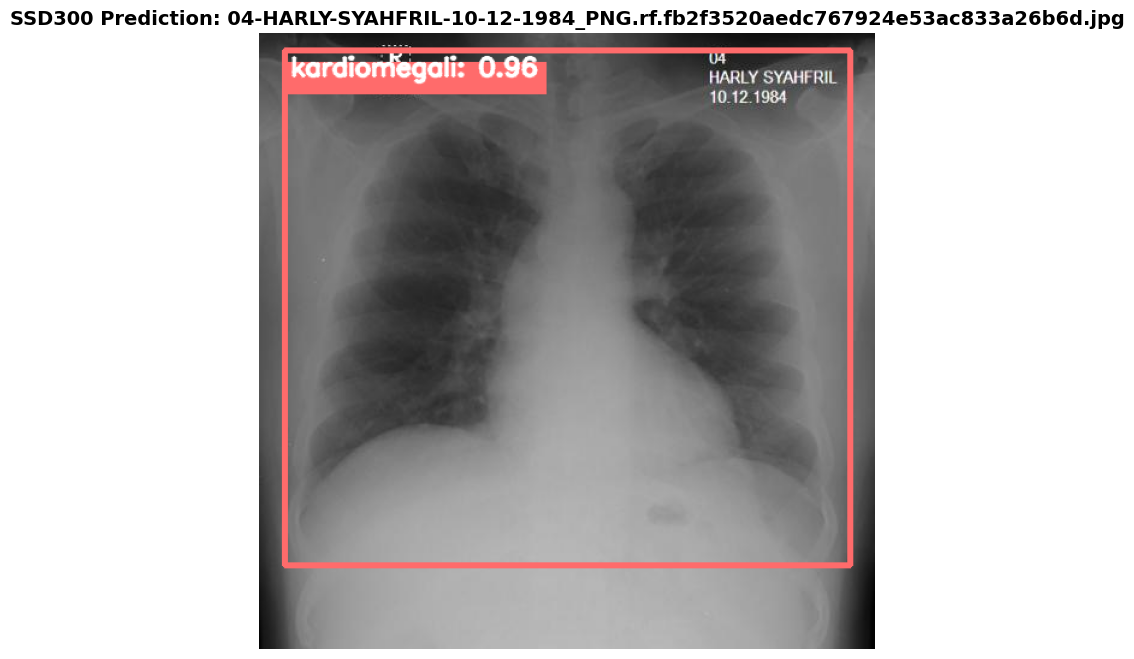

Saved to: outputs/ssd_inference/ssd_inference_3.png

Image 4/6
File: BENNY-FERDIAN_JPG.rf.0af8a523926677d56f8e8f44549946ba.jpg


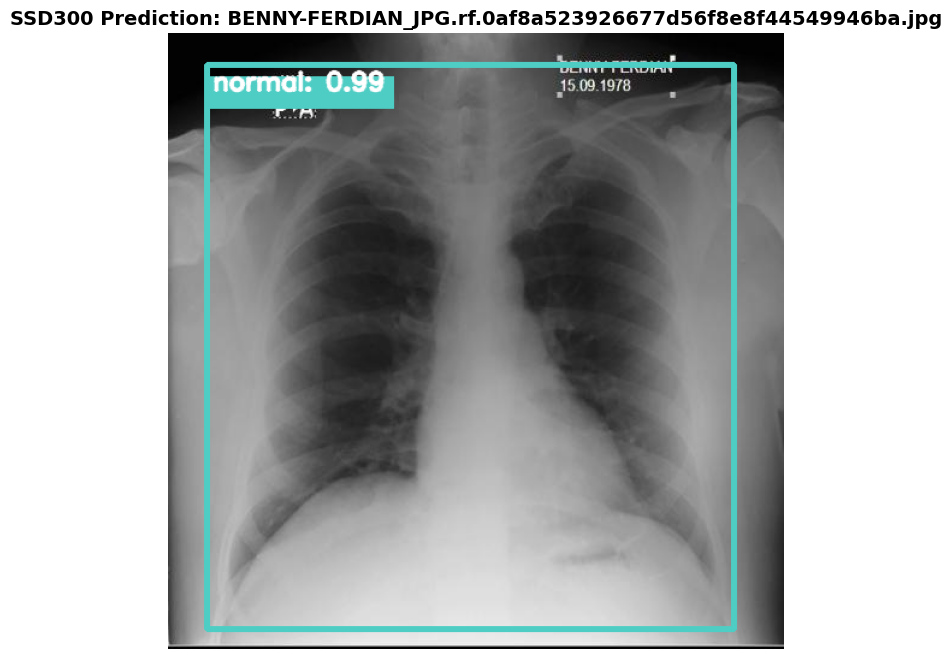

Saved to: outputs/ssd_inference/ssd_inference_4.png

Image 5/6
File: 49-TONI-ARDI-12-11-1996_PNG.rf.04e43c9e77b46c1aaa588d8130c603b6.jpg


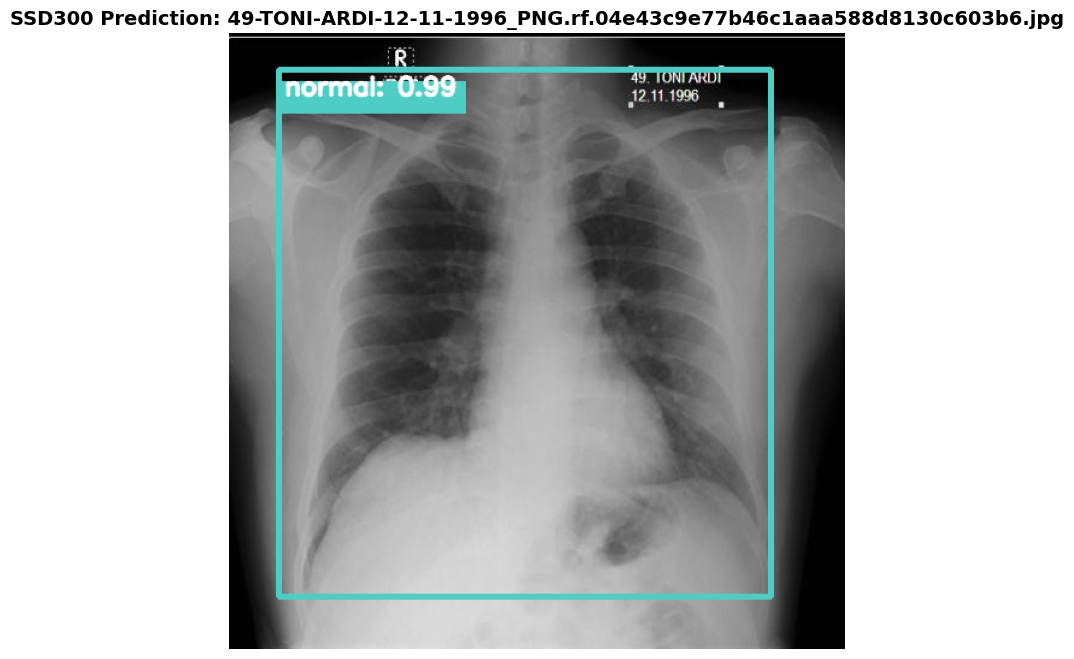

Saved to: outputs/ssd_inference/ssd_inference_5.png

Image 6/6
File: 171-YASRIZAL-20-09-1995_jpg.rf.82d3e0ddcf77674589d9fc94f1c52bd8.jpg


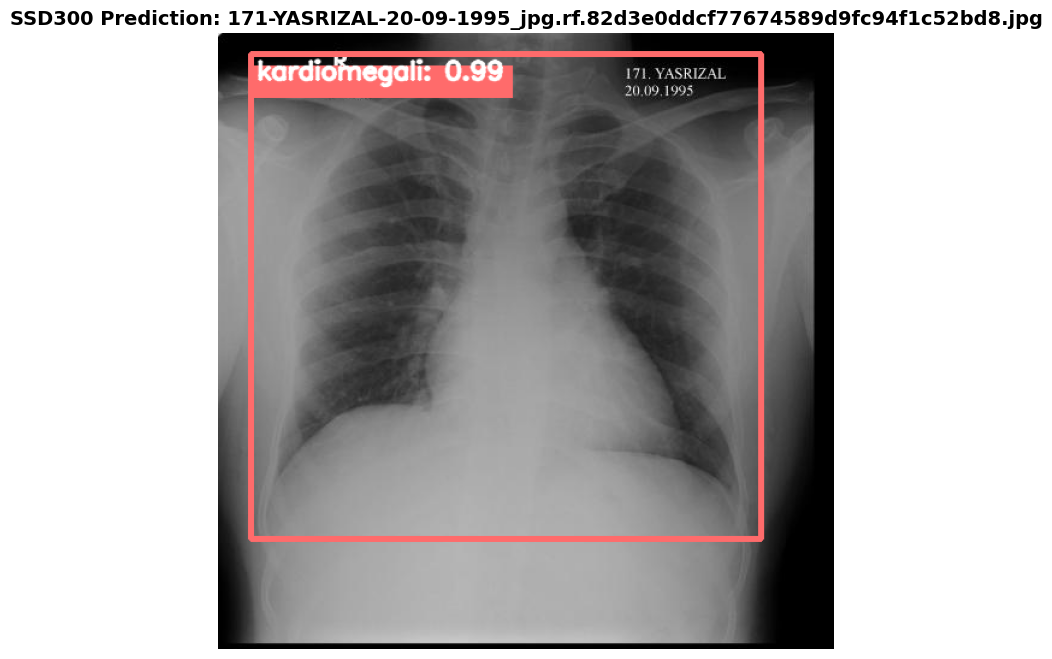

Saved to: outputs/ssd_inference/ssd_inference_6.png


In [32]:
import cv2
import random
import matplotlib.pyplot as plt
import torchvision.transforms as T

from PIL import Image

import torch

# load SSD model
ssd_model.load_state_dict(
    torch.load(
        SSD_CKPT,
        map_location=DEVICE,
        weights_only=True
    )
)

ssd_model.eval().to(DEVICE)

# output directory
SSD_INFERENCE_DIR = (
    OUTPUT_DIR / 'ssd_inference'
)

SSD_INFERENCE_DIR.mkdir(
    exist_ok=True
)

# color map
colors_map = {

    0: (255, 107, 107),   # kardiomegali

    1: (78, 205, 196)     # normal
}

# transform
transform_ssd = T.Compose([

    T.Resize(
        (SSD_SIZE, SSD_SIZE)
    ),

    T.ToTensor(),

    T.Normalize(

        [0.485, 0.456, 0.406],

        [0.229, 0.224, 0.225]
    )
])

# draw label
def draw_label(
    img,
    text,
    x1,
    y1,
    color
):

    font = cv2.FONT_HERSHEY_SIMPLEX

    font_scale = 0.7

    thickness = 2

    text_size, _ = cv2.getTextSize(

        text,

        font,

        font_scale,

        thickness
    )

    text_w, text_h = text_size

    # jika terlalu atas → pindah ke bawah
    if y1 - text_h - 15 < 0:

        label_y1 = y1 + 10

        label_y2 = y1 + text_h + 20

        text_y = y1 + text_h + 5

    else:

        label_y1 = y1 - text_h - 15

        label_y2 = y1

        text_y = y1 - 8

    # background
    cv2.rectangle(

        img,

        (x1, label_y1),

        (x1 + text_w + 10, label_y2),

        color,

        -1
    )

    # text
    cv2.putText(

        img,

        text,

        (x1 + 5, text_y),

        font,

        font_scale,

        (255, 255, 255),

        thickness,

        cv2.LINE_AA
    )

# SSD inference
def run_ssd_inference_and_visualize(
    image_path,
    save_path=None
):

    # read original image
    orig_img = cv2.imread(
        str(image_path)
    )

    orig_img = cv2.cvtColor(
        orig_img,
        cv2.COLOR_BGR2RGB
    )

    h, w = orig_img.shape[:2]

    # PIL image
    pil_img = Image.open(
        image_path
    ).convert('RGB')

    # transform
    img_tensor = transform_ssd(
        pil_img
    ).unsqueeze(0).to(DEVICE)

    # predict
    with torch.no_grad():

        prediction = ssd_model(
            img_tensor
        )[0]

    # confidence filter
    keep = (
        prediction['scores'] >= 0.5
    )

    boxes = (
        prediction['boxes'][keep]
        .cpu()
        .numpy()
    )

    scores = (
        prediction['scores'][keep]
        .cpu()
        .numpy()
    )

    labels = (
        prediction['labels'][keep]
        .cpu()
        .numpy()
    )

    # draw predictions
    for box, score, label in zip(
        boxes,
        scores,
        labels
    ):

        cls = int(label) - 1

        x1, y1, x2, y2 = box

        # resize back to original
        x1 = int(x1 * w / SSD_SIZE)

        y1 = int(y1 * h / SSD_SIZE)

        x2 = int(x2 * w / SSD_SIZE)

        y2 = int(y2 * h / SSD_SIZE)

        color = colors_map[cls]

        # bbox
        cv2.rectangle(

            orig_img,

            (x1, y1),

            (x2, y2),

            color,

            3
        )

        # label
        text = (
            f'{CLASS_NAMES[cls]}: '
            f'{score:.2f}'
        )

        draw_label(

            orig_img,

            text,

            x1,

            y1,

            color
        )

    # display
    plt.figure(figsize=(10, 8))

    plt.imshow(orig_img)

    plt.axis('off')

    plt.title(

        f'SSD300 Prediction: {image_path.name}',

        fontsize=14,

        fontweight='bold'
    )

    # save
    if save_path:

        plt.savefig(

            save_path,

            dpi=300,

            bbox_inches='tight'
        )

    plt.show()

# Sample images
test_image_files = sorted(
    list(TEST_IMG.glob('*'))
)

print(
    'Running SSD300 inference '
    'on sample test images...\n'
)

sample_test_images = random.sample(

    test_image_files,

    min(6, len(test_image_files))
)

for idx, img_path in enumerate(
    sample_test_images
):

    print(
        f'\nImage '
        f'{idx + 1}/'
        f'{len(sample_test_images)}'
    )

    print(f'File: {img_path.name}')

    save_path = (

        SSD_INFERENCE_DIR

        / f'ssd_inference_{idx + 1}.png'
    )

    run_ssd_inference_and_visualize(

        img_path,

        save_path
    )

    print(f'Saved to: {save_path}')

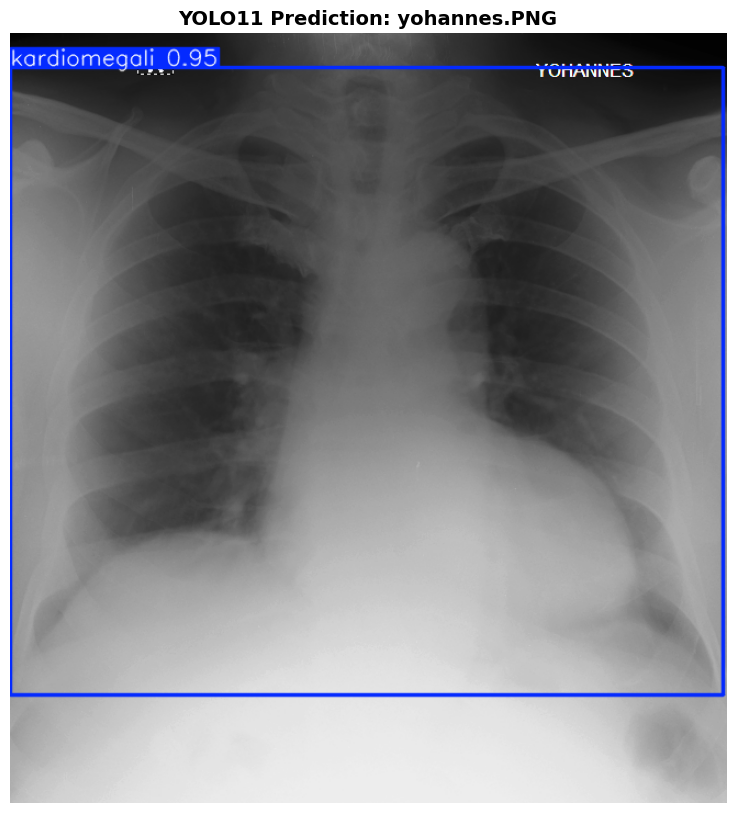

In [34]:
from ultralytics import YOLO

import matplotlib.pyplot as plt
import cv2

# Load best YOLO11 model
model_yolo11 = YOLO(
    str(YOLO_BEST)
)

# Image path
image_path = 'yohannes.PNG'

# Prediction
results = model_yolo11.predict(

    source=image_path,

    conf=0.25,

    device=DEVICE,

    save=False,

    verbose=False
)

# Visualization
res_plotted = results[0].plot()

# Convert BGR -> RGB
res_rgb = cv2.cvtColor(

    res_plotted,

    cv2.COLOR_BGR2RGB
)

# Display
plt.figure(figsize=(10, 10))

plt.imshow(res_rgb)

plt.axis('off')

plt.title(

    f'YOLO11 Prediction: {image_path}',

    fontsize=14,

    fontweight='bold'
)

plt.show()

In [35]:
result = results[0]

print(f'Ditemukan {len(result.boxes)} objek pada gambar.\n')

for idx, box in enumerate(result.boxes):

    # Bounding Box
    coords = box.xyxy[0].tolist()

    # Confidence
    confidence = float(box.conf[0].item())

    # Class
    class_id = int(box.cls[0].item())
    class_name = CLASS_NAMES[class_id]

    print(f'Object #{idx+1}')
    print('-' * 40)

    print(f'Class      : {class_name}')
    print(f'Confidence : {confidence:.4f} ({confidence*100:.2f}%)')
    print(f'Bounding Box Coordinates:')
    print(f'  x1={coords[0]:.2f}')
    print(f'  y1={coords[1]:.2f}')
    print(f'  x2={coords[2]:.2f}')
    print(f'  y2={coords[3]:.2f}')

    print()

Ditemukan 1 objek pada gambar.

Object #1
----------------------------------------
Class      : kardiomegali
Confidence : 0.9472 (94.72%)
Bounding Box Coordinates:
  x1=0.00
  y1=31.94
  x2=649.21
  y2=603.69



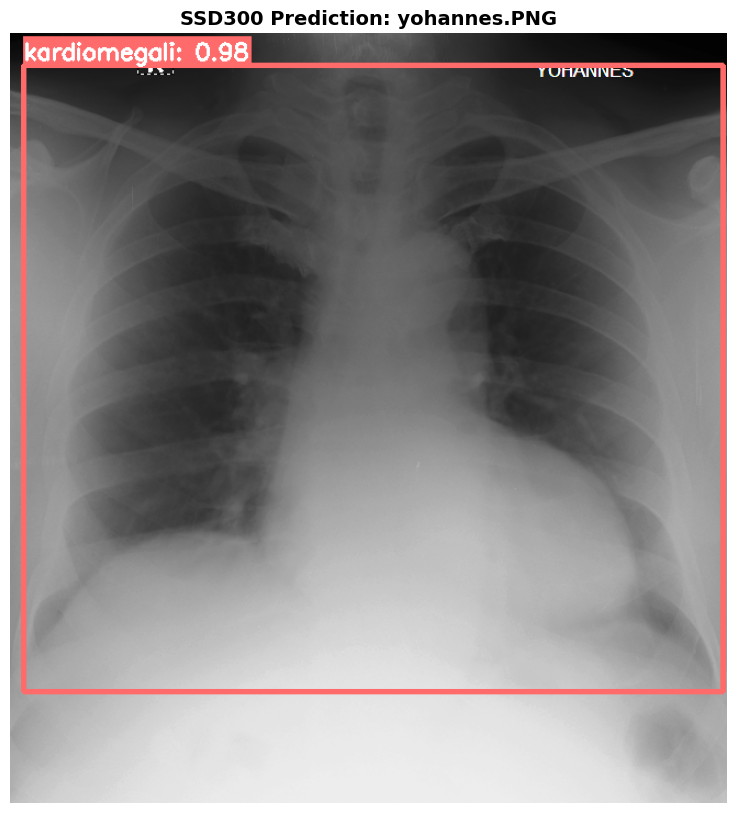

In [36]:
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image

# =========================
# LOAD SSD MODEL
# =========================
ssd_model.load_state_dict(
    torch.load(SSD_CKPT, map_location=DEVICE, weights_only=True)
)

ssd_model.eval().to(DEVICE)

# =========================
# IMAGE PATH
# =========================
image_path = 'yohannes.PNG' 

# =========================
# TRANSFORM
# =========================
transform_ssd = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225])
])

# =========================
# LOAD IMAGE
# =========================
orig_img = cv2.imread(image_path)
orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

h, w = orig_img.shape[:2]

pil_img = Image.open(image_path).convert('RGB')

img_tensor = transform_ssd(pil_img).unsqueeze(0).to(DEVICE)

# =========================
# PREDICT
# =========================
with torch.no_grad():
    prediction = ssd_model(img_tensor)[0]

# =========================
# FILTER CONFIDENCE
# =========================
keep = prediction['scores'] >= 0.25

boxes  = prediction['boxes'][keep].cpu().numpy()
scores = prediction['scores'][keep].cpu().numpy()
labels = prediction['labels'][keep].cpu().numpy()

# =========================
# COLOR MAP
# =========================
colors_map = {
    0: (255, 107, 107),
    1: (78, 205, 196)
}

# =========================
# DRAW PREDICTIONS
# =========================
for box, score, label in zip(boxes, scores, labels):

    cls = int(label) - 1

    x1, y1, x2, y2 = box

    # Scale back to original image size
    x1 = int(x1 * w / SSD_SIZE)
    y1 = int(y1 * h / SSD_SIZE)
    x2 = int(x2 * w / SSD_SIZE)
    y2 = int(y2 * h / SSD_SIZE)

    color = colors_map[cls]

    # Draw bounding box
    cv2.rectangle(orig_img, (x1, y1), (x2, y2), color, 3)

    # Label
    text = f'{CLASS_NAMES[cls]}: {score:.2f}'

    label_size, _ = cv2.getTextSize(
        text,
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        2
    )

    cv2.rectangle(
        orig_img,
        (x1, y1 - label_size[1] - 10),
        (x1 + label_size[0], y1),
        color,
        -1
    )

    cv2.putText(
        orig_img,
        text,
        (x1, y1 - 5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255,255,255),
        2
    )

# =========================
# SHOW RESULT
# =========================
plt.figure(figsize=(10,10))

plt.imshow(orig_img)
plt.axis('off')

plt.title(
    f'SSD300 Prediction: {image_path}',
    fontsize=14,
    fontweight='bold'
)

plt.show()

In [37]:
print(f'Ditemukan {len(boxes)} objek pada gambar.\n')

for idx, (box, score, label) in enumerate(zip(boxes, scores, labels)):

    cls = int(label) - 1

    print(f'Object #{idx+1}')
    print('-' * 40)

    print(f'Class      : {CLASS_NAMES[cls]}')
    print(f'Confidence : {score:.4f} ({score*100:.2f}%)')

    print('Bounding Box Coordinates:')
    print(f'  x1={box[0]:.2f}')
    print(f'  y1={box[1]:.2f}')
    print(f'  x2={box[2]:.2f}')
    print(f'  y2={box[3]:.2f}')

    print()

Ditemukan 1 objek pada gambar.

Object #1
----------------------------------------
Class      : kardiomegali
Confidence : 0.9769 (97.69%)
Bounding Box Coordinates:
  x1=5.95
  y1=12.61
  x2=298.56
  y2=256.79



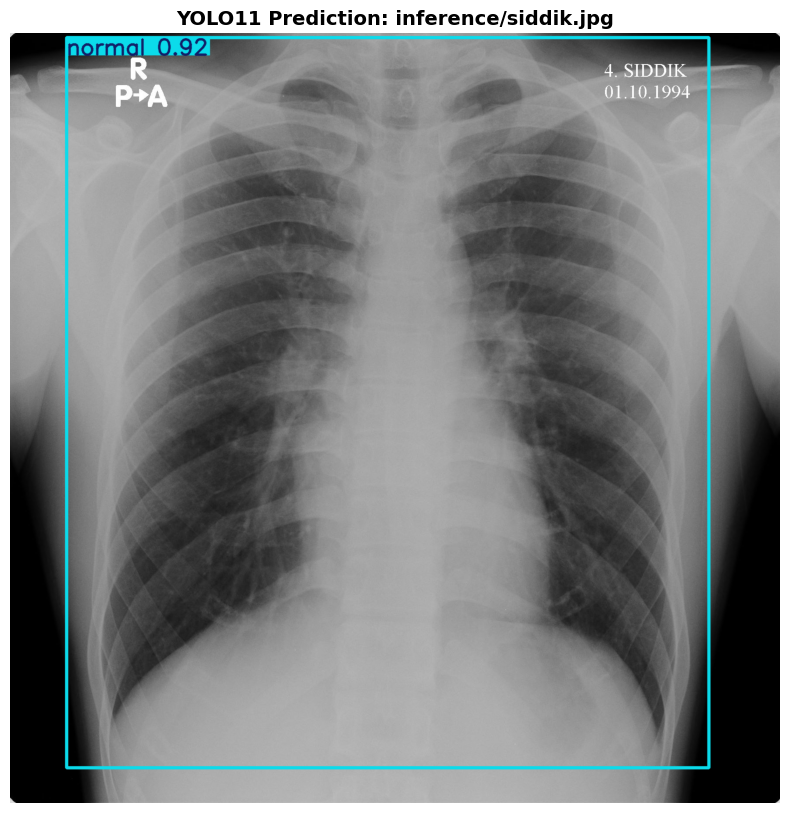

In [39]:
from ultralytics import YOLO

import matplotlib.pyplot as plt
import cv2

# Load best YOLO11 model
model_yolo11 = YOLO(
    str(YOLO_BEST)
)

# Image path
image_path = Path('inference') / 'siddik.jpg'

# Prediction
results = model_yolo11.predict(

    source=image_path,

    conf=0.25,

    device=DEVICE,

    save=False,

    verbose=False
)

# Visualization
res_plotted = results[0].plot()

# Convert BGR -> RGB
res_rgb = cv2.cvtColor(

    res_plotted,

    cv2.COLOR_BGR2RGB
)

# Display
plt.figure(figsize=(10, 10))

plt.imshow(res_rgb)

plt.axis('off')

plt.title(

    f'YOLO11 Prediction: {image_path}',

    fontsize=14,

    fontweight='bold'
)

plt.show()

In [ ]:
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image

# =========================
# LOAD SSD MODEL
# =========================
ssd_model.load_state_dict(
    torch.load(SSD_CKPT, map_location=DEVICE, weights_only=True)
)

ssd_model.eval().to(DEVICE)

# =========================
# IMAGE PATH
# =========================
image_path = 'yohannes.PNG' 

# =========================
# TRANSFORM
# =========================
transform_ssd = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225])
])

# =========================
# LOAD IMAGE
# =========================
orig_img = cv2.imread(image_path)
orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

h, w = orig_img.shape[:2]

pil_img = Image.open(image_path).convert('RGB')

img_tensor = transform_ssd(pil_img).unsqueeze(0).to(DEVICE)

# =========================
# PREDICT
# =========================
with torch.no_grad():
    prediction = ssd_model(img_tensor)[0]

# =========================
# FILTER CONFIDENCE
# =========================
keep = prediction['scores'] >= 0.25

boxes  = prediction['boxes'][keep].cpu().numpy()
scores = prediction['scores'][keep].cpu().numpy()
labels = prediction['labels'][keep].cpu().numpy()

# =========================
# COLOR MAP
# =========================
colors_map = {
    0: (255, 107, 107),
    1: (78, 205, 196)
}

# =========================
# DRAW PREDICTIONS
# =========================
for box, score, label in zip(boxes, scores, labels):

    cls = int(label) - 1

    x1, y1, x2, y2 = box

    # Scale back to original image size
    x1 = int(x1 * w / SSD_SIZE)
    y1 = int(y1 * h / SSD_SIZE)
    x2 = int(x2 * w / SSD_SIZE)
    y2 = int(y2 * h / SSD_SIZE)

    color = colors_map[cls]

    # Draw bounding box
    cv2.rectangle(orig_img, (x1, y1), (x2, y2), color, 3)

    # Label
    text = f'{CLASS_NAMES[cls]}: {score:.2f}'

    label_size, _ = cv2.getTextSize(
        text,
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        2
    )

    cv2.rectangle(
        orig_img,
        (x1, y1 - label_size[1] - 10),
        (x1 + label_size[0], y1),
        color,
        -1
    )

    cv2.putText(
        orig_img,
        text,
        (x1, y1 - 5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255,255,255),
        2
    )

# =========================
# SHOW RESULT
# =========================
plt.figure(figsize=(10,10))

plt.imshow(orig_img)
plt.axis('off')

plt.title(
    f'SSD300 Prediction: {image_path}',
    fontsize=14,
    fontweight='bold'
)

plt.show()

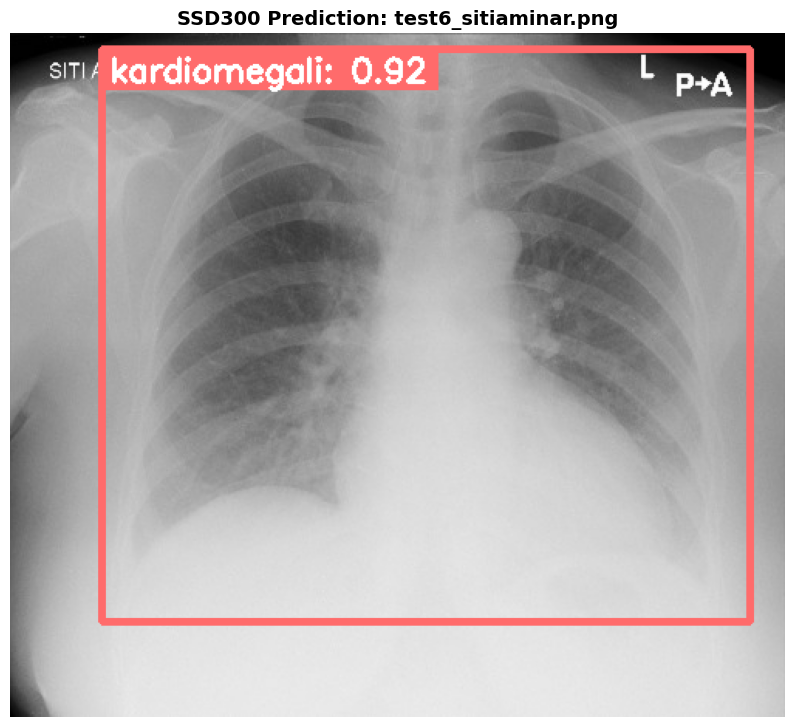

In [40]:
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image
from pathlib import Path

# =========================
# LOAD SSD MODEL
# =========================
ssd_model.load_state_dict(
    torch.load(
        SSD_CKPT,
        map_location=DEVICE,
        weights_only=True
    )
)

ssd_model.eval().to(DEVICE)

# =========================
# IMAGE PATH
# =========================
image_path = Path('predict') / 'test6_sitiaminar.png'

# =========================
# TRANSFORM
# =========================
transform_ssd = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# =========================
# LOAD IMAGE
# =========================
orig_img = cv2.imread(str(image_path))
orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

h, w = orig_img.shape[:2]

pil_img = Image.open(image_path).convert('RGB')

img_tensor = transform_ssd(pil_img).unsqueeze(0).to(DEVICE)

# =========================
# PREDICT
# =========================
with torch.no_grad():
    prediction = ssd_model(img_tensor)[0]

# =========================
# FILTER CONFIDENCE
# =========================
CONF_THRESHOLD = 0.50

keep = prediction['scores'] >= CONF_THRESHOLD

boxes  = prediction['boxes'][keep].cpu().numpy()
scores = prediction['scores'][keep].cpu().numpy()
labels = prediction['labels'][keep].cpu().numpy()

# =========================
# COLOR MAP
# =========================
colors_map = {
    0: (255, 107, 107),   # merah
    1: (78, 205, 196)    # hijau
}

# =========================
# DRAW PREDICTIONS
# =========================
for box, score, label in zip(boxes, scores, labels):

    cls = int(label) - 1

    # Bounding box SSD output
    x1, y1, x2, y2 = box

    # =========================
    # SCALE TO ORIGINAL IMAGE
    # =========================
    x1 = int(x1 * w / SSD_SIZE)
    y1 = int(y1 * h / SSD_SIZE)
    x2 = int(x2 * w / SSD_SIZE)
    y2 = int(y2 * h / SSD_SIZE)

    # Clamp supaya tidak keluar gambar
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)

    color = colors_map[cls]

    # =========================
    # DRAW BOUNDING BOX
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, y1),
        (x2, y2),
        color,
        3
    )

    # =========================
    # LABEL TEXT
    # =========================
    text = f'{CLASS_NAMES[cls]}: {score:.2f}'

    label_size, _ = cv2.getTextSize(
        text,
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        2
    )

    text_w, text_h = label_size

    # =========================
    # FIX LABEL POSITION
    # =========================
    # Jika terlalu dekat atas gambar
    # label dipindahkan ke bawah
    if y1 - text_h - 10 < 0:

        label_y1 = y1
        label_y2 = y1 + text_h + 10

        text_x = x1
        text_y = y1 + text_h + 5

    else:

        label_y1 = y1 - text_h - 10
        label_y2 = y1

        text_x = x1
        text_y = y1 - 5

    # =========================
    # DRAW LABEL BACKGROUND
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, label_y1),
        (x1 + text_w + 10, label_y2),
        color,
        -1
    )

    # =========================
    # DRAW TEXT
    # =========================
    cv2.putText(
        orig_img,
        text,
        (text_x + 5, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

# =========================
# SHOW RESULT
# =========================
plt.figure(figsize=(10,10))

plt.imshow(orig_img)

plt.axis('off')

plt.title(
    f'SSD300 Prediction: {image_path.name}',
    fontsize=14,
    fontweight='bold'
)

plt.show()

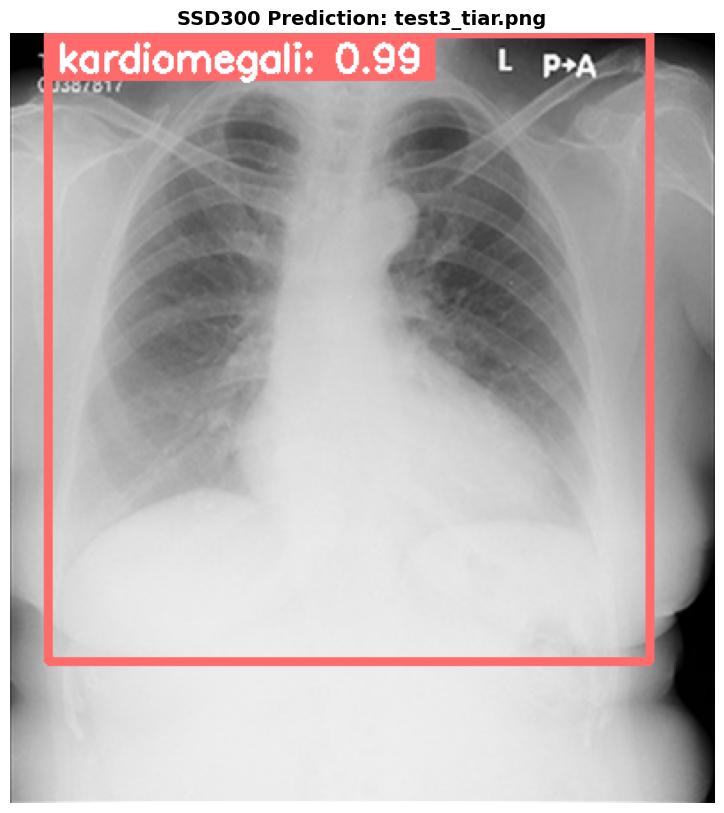

In [41]:
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image
from pathlib import Path

# =========================
# LOAD SSD MODEL
# =========================
ssd_model.load_state_dict(
    torch.load(
        SSD_CKPT,
        map_location=DEVICE,
        weights_only=True
    )
)

ssd_model.eval().to(DEVICE)

# =========================
# IMAGE PATH
# =========================
image_path = Path('predict') / 'test3_tiar.png'

# =========================
# TRANSFORM
# =========================
transform_ssd = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# =========================
# LOAD IMAGE
# =========================
orig_img = cv2.imread(str(image_path))
orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

h, w = orig_img.shape[:2]

pil_img = Image.open(image_path).convert('RGB')

img_tensor = transform_ssd(pil_img).unsqueeze(0).to(DEVICE)

# =========================
# PREDICT
# =========================
with torch.no_grad():
    prediction = ssd_model(img_tensor)[0]

# =========================
# FILTER CONFIDENCE
# =========================
CONF_THRESHOLD = 0.50

keep = prediction['scores'] >= CONF_THRESHOLD

boxes  = prediction['boxes'][keep].cpu().numpy()
scores = prediction['scores'][keep].cpu().numpy()
labels = prediction['labels'][keep].cpu().numpy()

# =========================
# COLOR MAP
# =========================
colors_map = {
    0: (255, 107, 107),   # merah
    1: (78, 205, 196)    # hijau
}

# =========================
# DRAW PREDICTIONS
# =========================
for box, score, label in zip(boxes, scores, labels):

    cls = int(label) - 1

    # Bounding box SSD output
    x1, y1, x2, y2 = box

    # =========================
    # SCALE TO ORIGINAL IMAGE
    # =========================
    x1 = int(x1 * w / SSD_SIZE)
    y1 = int(y1 * h / SSD_SIZE)
    x2 = int(x2 * w / SSD_SIZE)
    y2 = int(y2 * h / SSD_SIZE)

    # Clamp supaya tidak keluar gambar
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)

    color = colors_map[cls]

    # =========================
    # DRAW BOUNDING BOX
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, y1),
        (x2, y2),
        color,
        3
    )

    # =========================
    # LABEL TEXT
    # =========================
    text = f'{CLASS_NAMES[cls]}: {score:.2f}'

    label_size, _ = cv2.getTextSize(
        text,
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        2
    )

    text_w, text_h = label_size

    # =========================
    # FIX LABEL POSITION
    # =========================
    # Jika terlalu dekat atas gambar
    # label dipindahkan ke bawah
    if y1 - text_h - 10 < 0:

        label_y1 = y1
        label_y2 = y1 + text_h + 10

        text_x = x1
        text_y = y1 + text_h + 5

    else:

        label_y1 = y1 - text_h - 10
        label_y2 = y1

        text_x = x1
        text_y = y1 - 5

    # =========================
    # DRAW LABEL BACKGROUND
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, label_y1),
        (x1 + text_w + 10, label_y2),
        color,
        -1
    )

    # =========================
    # DRAW TEXT
    # =========================
    cv2.putText(
        orig_img,
        text,
        (text_x + 5, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

# =========================
# SHOW RESULT
# =========================
plt.figure(figsize=(10,10))

plt.imshow(orig_img)

plt.axis('off')

plt.title(
    f'SSD300 Prediction: {image_path.name}',
    fontsize=14,
    fontweight='bold'
)

plt.show()

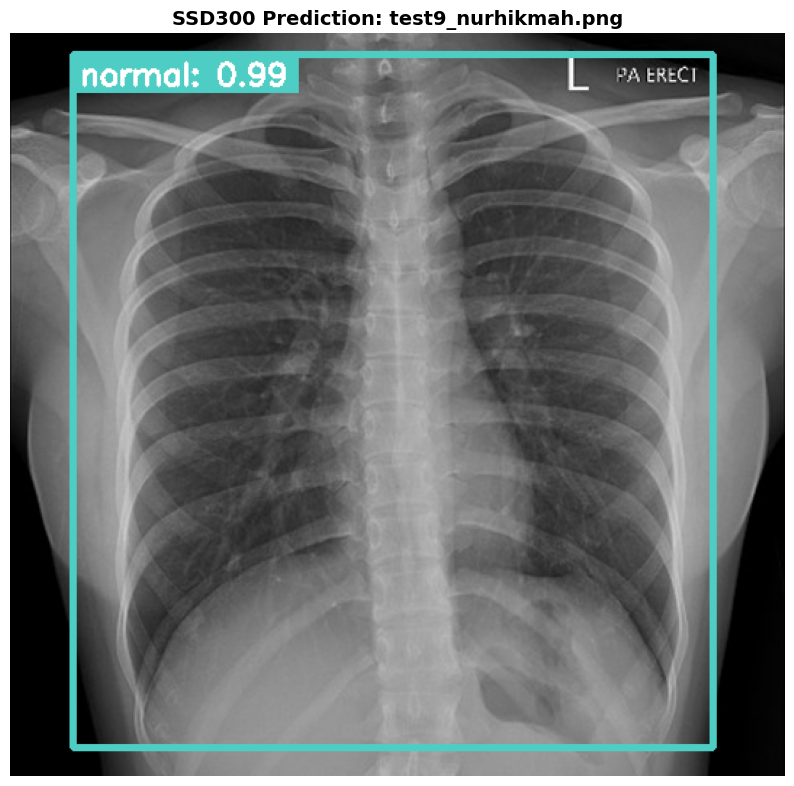

In [44]:
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image
from pathlib import Path

# =========================
# LOAD SSD MODEL
# =========================
ssd_model.load_state_dict(
    torch.load(
        SSD_CKPT,
        map_location=DEVICE,
        weights_only=True
    )
)

ssd_model.eval().to(DEVICE)

# =========================
# IMAGE PATH
# =========================
image_path = Path('predict') / 'test9_nurhikmah.png'

# =========================
# TRANSFORM
# =========================
transform_ssd = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# =========================
# LOAD IMAGE
# =========================
orig_img = cv2.imread(str(image_path))
orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

h, w = orig_img.shape[:2]

pil_img = Image.open(image_path).convert('RGB')

img_tensor = transform_ssd(pil_img).unsqueeze(0).to(DEVICE)

# =========================
# PREDICT
# =========================
with torch.no_grad():
    prediction = ssd_model(img_tensor)[0]

# =========================
# FILTER CONFIDENCE
# =========================
CONF_THRESHOLD = 0.50

keep = prediction['scores'] >= CONF_THRESHOLD

boxes  = prediction['boxes'][keep].cpu().numpy()
scores = prediction['scores'][keep].cpu().numpy()
labels = prediction['labels'][keep].cpu().numpy()

# =========================
# COLOR MAP
# =========================
colors_map = {
    0: (255, 107, 107),   # merah
    1: (78, 205, 196)    # hijau
}

# =========================
# DRAW PREDICTIONS
# =========================
for box, score, label in zip(boxes, scores, labels):

    cls = int(label) - 1

    # Bounding box SSD output
    x1, y1, x2, y2 = box

    # =========================
    # SCALE TO ORIGINAL IMAGE
    # =========================
    x1 = int(x1 * w / SSD_SIZE)
    y1 = int(y1 * h / SSD_SIZE)
    x2 = int(x2 * w / SSD_SIZE)
    y2 = int(y2 * h / SSD_SIZE)

    # Clamp supaya tidak keluar gambar
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)

    color = colors_map[cls]

    # =========================
    # DRAW BOUNDING BOX
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, y1),
        (x2, y2),
        color,
        3
    )

    # =========================
    # LABEL TEXT
    # =========================
    text = f'{CLASS_NAMES[cls]}: {score:.2f}'

    label_size, _ = cv2.getTextSize(
        text,
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        2
    )

    text_w, text_h = label_size

    # =========================
    # FIX LABEL POSITION
    # =========================
    # Jika terlalu dekat atas gambar
    # label dipindahkan ke bawah
    if y1 - text_h - 10 < 0:

        label_y1 = y1
        label_y2 = y1 + text_h + 10

        text_x = x1
        text_y = y1 + text_h + 5

    else:

        label_y1 = y1 - text_h - 10
        label_y2 = y1

        text_x = x1
        text_y = y1 - 5

    # =========================
    # DRAW LABEL BACKGROUND
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, label_y1),
        (x1 + text_w + 10, label_y2),
        color,
        -1
    )

    # =========================
    # DRAW TEXT
    # =========================
    cv2.putText(
        orig_img,
        text,
        (text_x + 5, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

# =========================
# SHOW RESULT
# =========================
plt.figure(figsize=(10,10))

plt.imshow(orig_img)

plt.axis('off')

plt.title(
    f'SSD300 Prediction: {image_path.name}',
    fontsize=14,
    fontweight='bold'
)

plt.show()

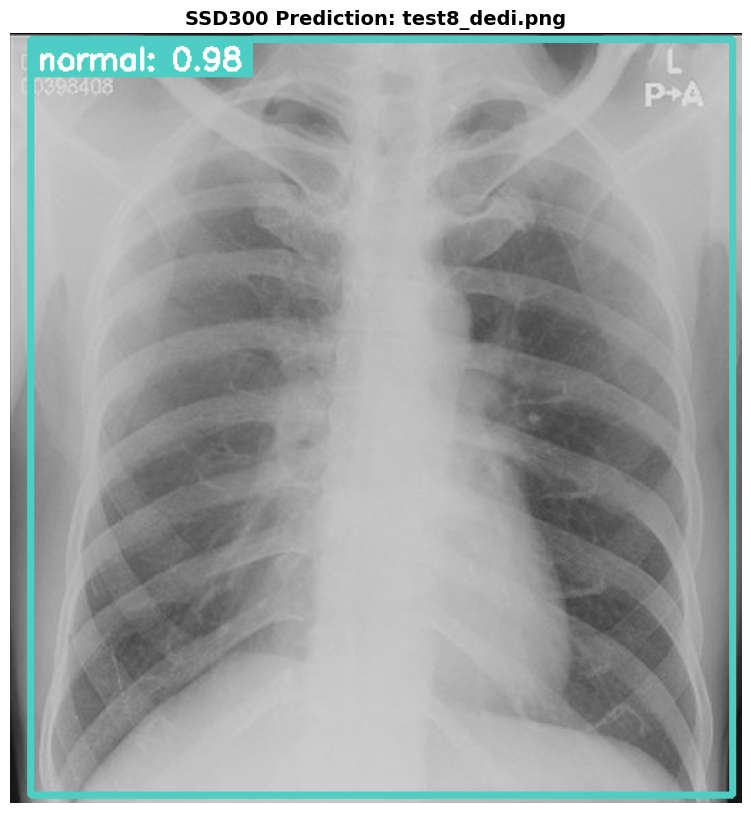

In [45]:
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image
from pathlib import Path

# =========================
# LOAD SSD MODEL
# =========================
ssd_model.load_state_dict(
    torch.load(
        SSD_CKPT,
        map_location=DEVICE,
        weights_only=True
    )
)

ssd_model.eval().to(DEVICE)

# =========================
# IMAGE PATH
# =========================
image_path = Path('predict') / 'test8_dedi.png'

# =========================
# TRANSFORM
# =========================
transform_ssd = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# =========================
# LOAD IMAGE
# =========================
orig_img = cv2.imread(str(image_path))
orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

h, w = orig_img.shape[:2]

pil_img = Image.open(image_path).convert('RGB')

img_tensor = transform_ssd(pil_img).unsqueeze(0).to(DEVICE)

# =========================
# PREDICT
# =========================
with torch.no_grad():
    prediction = ssd_model(img_tensor)[0]

# =========================
# FILTER CONFIDENCE
# =========================
CONF_THRESHOLD = 0.50

keep = prediction['scores'] >= CONF_THRESHOLD

boxes  = prediction['boxes'][keep].cpu().numpy()
scores = prediction['scores'][keep].cpu().numpy()
labels = prediction['labels'][keep].cpu().numpy()

# =========================
# COLOR MAP
# =========================
colors_map = {
    0: (255, 107, 107),   # merah
    1: (78, 205, 196)    # hijau
}

# =========================
# DRAW PREDICTIONS
# =========================
for box, score, label in zip(boxes, scores, labels):

    cls = int(label) - 1

    # Bounding box SSD output
    x1, y1, x2, y2 = box

    # =========================
    # SCALE TO ORIGINAL IMAGE
    # =========================
    x1 = int(x1 * w / SSD_SIZE)
    y1 = int(y1 * h / SSD_SIZE)
    x2 = int(x2 * w / SSD_SIZE)
    y2 = int(y2 * h / SSD_SIZE)

    # Clamp supaya tidak keluar gambar
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)

    color = colors_map[cls]

    # =========================
    # DRAW BOUNDING BOX
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, y1),
        (x2, y2),
        color,
        3
    )

    # =========================
    # LABEL TEXT
    # =========================
    text = f'{CLASS_NAMES[cls]}: {score:.2f}'

    label_size, _ = cv2.getTextSize(
        text,
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        2
    )

    text_w, text_h = label_size

    # =========================
    # FIX LABEL POSITION
    # =========================
    # Jika terlalu dekat atas gambar
    # label dipindahkan ke bawah
    if y1 - text_h - 10 < 0:

        label_y1 = y1
        label_y2 = y1 + text_h + 10

        text_x = x1
        text_y = y1 + text_h + 5

    else:

        label_y1 = y1 - text_h - 10
        label_y2 = y1

        text_x = x1
        text_y = y1 - 5

    # =========================
    # DRAW LABEL BACKGROUND
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, label_y1),
        (x1 + text_w + 10, label_y2),
        color,
        -1
    )

    # =========================
    # DRAW TEXT
    # =========================
    cv2.putText(
        orig_img,
        text,
        (text_x + 5, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

# =========================
# SHOW RESULT
# =========================
plt.figure(figsize=(10,10))

plt.imshow(orig_img)

plt.axis('off')

plt.title(
    f'SSD300 Prediction: {image_path.name}',
    fontsize=14,
    fontweight='bold'
)

plt.show()

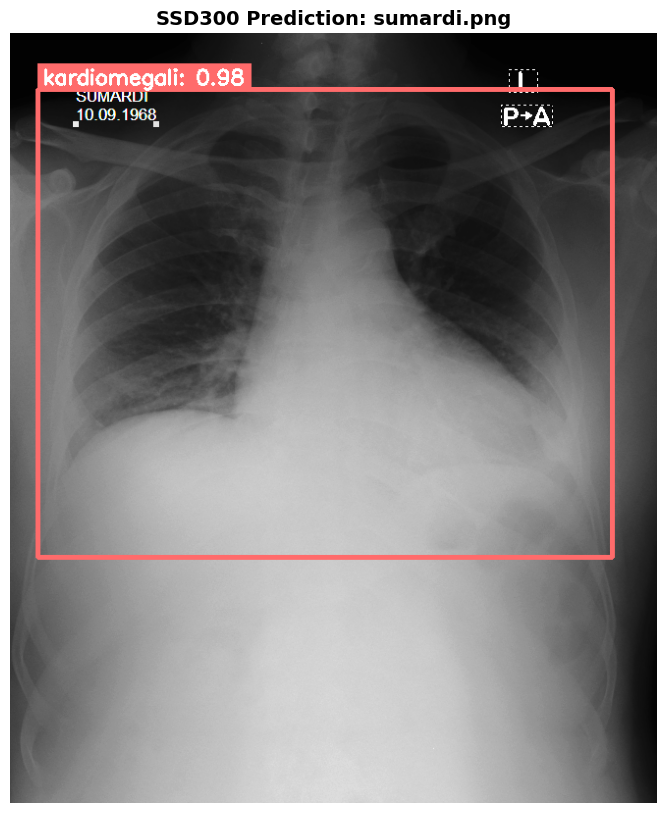

In [46]:
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image
from pathlib import Path

# =========================
# LOAD SSD MODEL
# =========================
ssd_model.load_state_dict(
    torch.load(
        SSD_CKPT,
        map_location=DEVICE,
        weights_only=True
    )
)

ssd_model.eval().to(DEVICE)

# =========================
# IMAGE PATH
# =========================
image_path = Path('inference') / 'sumardi.png'

# =========================
# TRANSFORM
# =========================
transform_ssd = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# =========================
# LOAD IMAGE
# =========================
orig_img = cv2.imread(str(image_path))
orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

h, w = orig_img.shape[:2]

pil_img = Image.open(image_path).convert('RGB')

img_tensor = transform_ssd(pil_img).unsqueeze(0).to(DEVICE)

# =========================
# PREDICT
# =========================
with torch.no_grad():
    prediction = ssd_model(img_tensor)[0]

# =========================
# FILTER CONFIDENCE
# =========================
CONF_THRESHOLD = 0.50

keep = prediction['scores'] >= CONF_THRESHOLD

boxes  = prediction['boxes'][keep].cpu().numpy()
scores = prediction['scores'][keep].cpu().numpy()
labels = prediction['labels'][keep].cpu().numpy()

# =========================
# COLOR MAP
# =========================
colors_map = {
    0: (255, 107, 107),   # merah
    1: (78, 205, 196)    # hijau
}

# =========================
# DRAW PREDICTIONS
# =========================
for box, score, label in zip(boxes, scores, labels):

    cls = int(label) - 1

    # Bounding box SSD output
    x1, y1, x2, y2 = box

    # =========================
    # SCALE TO ORIGINAL IMAGE
    # =========================
    x1 = int(x1 * w / SSD_SIZE)
    y1 = int(y1 * h / SSD_SIZE)
    x2 = int(x2 * w / SSD_SIZE)
    y2 = int(y2 * h / SSD_SIZE)

    # Clamp supaya tidak keluar gambar
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)

    color = colors_map[cls]

    # =========================
    # DRAW BOUNDING BOX
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, y1),
        (x2, y2),
        color,
        3
    )

    # =========================
    # LABEL TEXT
    # =========================
    text = f'{CLASS_NAMES[cls]}: {score:.2f}'

    label_size, _ = cv2.getTextSize(
        text,
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        2
    )

    text_w, text_h = label_size

    # =========================
    # FIX LABEL POSITION
    # =========================
    # Jika terlalu dekat atas gambar
    # label dipindahkan ke bawah
    if y1 - text_h - 10 < 0:

        label_y1 = y1
        label_y2 = y1 + text_h + 10

        text_x = x1
        text_y = y1 + text_h + 5

    else:

        label_y1 = y1 - text_h - 10
        label_y2 = y1

        text_x = x1
        text_y = y1 - 5

    # =========================
    # DRAW LABEL BACKGROUND
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, label_y1),
        (x1 + text_w + 10, label_y2),
        color,
        -1
    )

    # =========================
    # DRAW TEXT
    # =========================
    cv2.putText(
        orig_img,
        text,
        (text_x + 5, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

# =========================
# SHOW RESULT
# =========================
plt.figure(figsize=(10,10))

plt.imshow(orig_img)

plt.axis('off')

plt.title(
    f'SSD300 Prediction: {image_path.name}',
    fontsize=14,
    fontweight='bold'
)

plt.show()

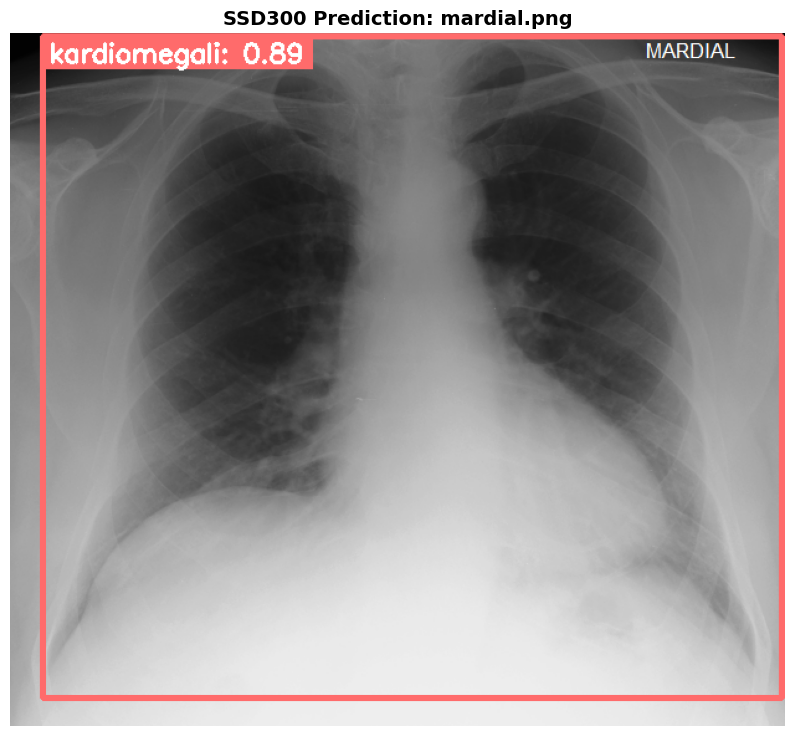

In [47]:
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image
from pathlib import Path

# =========================
# LOAD SSD MODEL
# =========================
ssd_model.load_state_dict(
    torch.load(
        SSD_CKPT,
        map_location=DEVICE,
        weights_only=True
    )
)

ssd_model.eval().to(DEVICE)

# =========================
# IMAGE PATH
# =========================
image_path = Path('inference') / 'mardial.png'

# =========================
# TRANSFORM
# =========================
transform_ssd = T.Compose([
    T.Resize((SSD_SIZE, SSD_SIZE)),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# =========================
# LOAD IMAGE
# =========================
orig_img = cv2.imread(str(image_path))
orig_img = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

h, w = orig_img.shape[:2]

pil_img = Image.open(image_path).convert('RGB')

img_tensor = transform_ssd(pil_img).unsqueeze(0).to(DEVICE)

# =========================
# PREDICT
# =========================
with torch.no_grad():
    prediction = ssd_model(img_tensor)[0]

# =========================
# FILTER CONFIDENCE
# =========================
CONF_THRESHOLD = 0.50

keep = prediction['scores'] >= CONF_THRESHOLD

boxes  = prediction['boxes'][keep].cpu().numpy()
scores = prediction['scores'][keep].cpu().numpy()
labels = prediction['labels'][keep].cpu().numpy()

# =========================
# COLOR MAP
# =========================
colors_map = {
    0: (255, 107, 107),   # merah
    1: (78, 205, 196)    # hijau
}

# =========================
# DRAW PREDICTIONS
# =========================
for box, score, label in zip(boxes, scores, labels):

    cls = int(label) - 1

    # Bounding box SSD output
    x1, y1, x2, y2 = box

    # =========================
    # SCALE TO ORIGINAL IMAGE
    # =========================
    x1 = int(x1 * w / SSD_SIZE)
    y1 = int(y1 * h / SSD_SIZE)
    x2 = int(x2 * w / SSD_SIZE)
    y2 = int(y2 * h / SSD_SIZE)

    # Clamp supaya tidak keluar gambar
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(w, x2)
    y2 = min(h, y2)

    color = colors_map[cls]

    # =========================
    # DRAW BOUNDING BOX
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, y1),
        (x2, y2),
        color,
        3
    )

    # =========================
    # LABEL TEXT
    # =========================
    text = f'{CLASS_NAMES[cls]}: {score:.2f}'

    label_size, _ = cv2.getTextSize(
        text,
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        2
    )

    text_w, text_h = label_size

    # =========================
    # FIX LABEL POSITION
    # =========================
    # Jika terlalu dekat atas gambar
    # label dipindahkan ke bawah
    if y1 - text_h - 10 < 0:

        label_y1 = y1
        label_y2 = y1 + text_h + 10

        text_x = x1
        text_y = y1 + text_h + 5

    else:

        label_y1 = y1 - text_h - 10
        label_y2 = y1

        text_x = x1
        text_y = y1 - 5

    # =========================
    # DRAW LABEL BACKGROUND
    # =========================
    cv2.rectangle(
        orig_img,
        (x1, label_y1),
        (x1 + text_w + 10, label_y2),
        color,
        -1
    )

    # =========================
    # DRAW TEXT
    # =========================
    cv2.putText(
        orig_img,
        text,
        (text_x + 5, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

# =========================
# SHOW RESULT
# =========================
plt.figure(figsize=(10,10))

plt.imshow(orig_img)

plt.axis('off')

plt.title(
    f'SSD300 Prediction: {image_path.name}',
    fontsize=14,
    fontweight='bold'
)

plt.show()